# Cost convexity controls the architecture of resistance-optimal networks

Executable supplement. It regenerates Tables II–VI, Figs. 1–7 and Supplemental
Table S1 from fixed graph seeds, and reports the numerical diagnostics alongside
the optimization results. Table I of the manuscript is analytic and has no
computational content. The nonconvex all-pairs calculations are best multistart
states, not certified global optima; every support size, cycle rank and crossover
reported for $\alpha<1$ is a property of the best state found at a stated search
budget. The single-pair control of Sec. X is evaluated from Thomson's principle
rather than read off a local numerical minimum.

**Changes relative to the previous release.** Three affect results rather than
presentation.

1. **Continuation in $\alpha$ replaces blind multistart as the search protocol.**
   Equal numbers of starts at different sizes is not equal search quality. At fixed
   $n$ the exponent is swept downward, the winning state at one exponent seeds the
   next, and the better of the blind and continued results is kept, so the outcome
   can only improve on the older protocol. `run_scaling` and `run_finite_size` both
   use it. Whether the blind protocol under- or over-counts loops is read off the
   `beta_blind` column of the outputs below rather than asserted here.
2. **Three new controls.** `run_insertion_test` opens a closed channel by a finite
   jump, the only move the divergent marginal price permits; `run_alpha_continuation`
   carries a looped state downward in $\alpha$ at fixed $n$; `run_alpha_star_line`
   localizes the loop collapse on a grid of step 0.005 at all eleven sizes and
   writes `alpha_star_summary.tsv`, from which the $\alpha^{*}(n)$ values of the
   manuscript are read.
3. **The threshold control is no longer circular.** It reruns the refinement from a
   pretruncation solution at each cut, which is what the earlier version's own
   caveat asked for.

Fixes that change no published number: the feasibility test in `lap_pinv` is
topological rather than spectral and returns a barrier direction instead of a zero
gradient; support pruning runs for $0<\alpha\le1$, since Sec. III gives a full
support only for $\alpha>1$ and an edge can be priced out at $\alpha=1$; the graph
specifications and $C_0$ of Table II are emitted by the module; `run_ensemble` is
renamed `run_loading` and reuses `spatial_graph`; $a_e$ is a parameter of the
barbell sensitivity. Regression checked: Tables II and III and
$\widetilde\kappa_{\max}/\widetilde\kappa_{\min}=144$ are unchanged, except the
"starts at best" entry at $\alpha=0.97$ in Table III, 6.3% to 7.8%, because the
barrier direction changes a few trajectories.


## 1. Setup and module

In [1]:
import os, sys, platform
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR', str(Path('.mpl_cache').resolve()))
os.environ.setdefault('XDG_CACHE_HOME', str(Path('.cache').resolve()))
Path(os.environ['MPLCONFIGDIR']).mkdir(exist_ok=True)
Path(os.environ['XDG_CACHE_HOME']).mkdir(exist_ok=True)
import numpy as np, pandas as pd, networkx as nx, matplotlib, matplotlib.pyplot as plt
import scipy
from IPython.display import Image, display
pd.set_option('display.width', 220)
print('Python', platform.python_version(), '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| networkx', nx.__version__, '| matplotlib', matplotlib.__version__,
      '| pandas', pd.__version__)

Python 3.13.15 | numpy 2.1.3 | scipy 1.16.3 | networkx 3.6.1 | matplotlib 3.10.0 | pandas 2.2.3


## Software environments and scope of the second-environment rerun

All results in the manuscript come from a single primary run of this notebook in
**Python 3.13.15, NumPy 2.1.3, SciPy 1.16.3, NetworkX 3.6.1, Matplotlib 3.10.0,
pandas 2.2.3**. The cell above prints the versions of whatever environment executes
the notebook, so a rerun elsewhere documents itself.

Part of the material was rerun independently in a **second environment: Python
3.12.3, NumPy 2.4.4, SciPy 1.17.1, NetworkX 3.6.1, Matplotlib 3.10.8, pandas 3.0.2**.
Every quantity rerun there agreed with the primary run to the printed precision,
including active-edge counts, cycle ranks and best resistances. The rerun covered:

- Table III in full (complete candidate graph, $n=12$, seven exponents, 64 starts).
- Table V (length-weighted spatial graph, seven rows, including the fixed-volume
  law $\alpha=1/2$, $a_e\propto\ell_e^{3/2}$). The rerun predates the change of the
  pruning gate to $\alpha\le1$, so its $\alpha=1$ row was obtained without the
  refinement stage; that row is the one entry of Table V not rerun under the
  shipped code.
- The finite-size scan of Fig. 2(b) at $n=8,12,16,20$, and the tree boundary at
  $n=32$ and $48$.
- The barbell sensitivity of Fig. 7.
- Both gradient checks of Sec. VI: central differences in the conductances
  ($2.5\times10^{-8}$) and the projected softmax gradient ($9.0\times10^{-8}$).
- The start-budget control at 28, 64 and 144 starts, reproducing $381.631590$
  ($\alpha=0.65$, $n=32$), $546.797241$ ($\alpha=0.65$, $n=40$) and the
  $178\to179$ shift at $\alpha=0.90$, $n=40$.
- The seeded continuation in $n$ from $n=28$ into $K_{32}$ and $K_{40}$.
- The $n=64$ states of the size scan at $\alpha=0.90$ (300 edges, $\beta=237$)
  and $\alpha=0.75$ (178 edges, $\beta=115$).

The following were run in the primary environment only and have not been
reproduced elsewhere: the remaining 42 states of the size scan (Table IV and
Supplemental Table S1), the loop-collapse exponent $\alpha^{*}(n)$ at grid step
0.005, the downward continuation in $\alpha$, the single-edge insertion test
(465 edges $\times$ 3 values of $\varepsilon$), the seed-robustness check, the
truncation-disabled threshold control, Table II, and Table VI.

The second-environment rerun was executed by Claude Opus 5 (Anthropic) using this
notebook's module without modification to any numerical routine; the palette,
typography and panel-label code of the figure functions were adjusted in that
session and are the versions shipped here. The authors verified all results and
take full responsibility for them.

In [2]:
%%writefile pre_all.py
"""Everything reported in the manuscript, from one optimizer and one set of seeds.

Manuscript items produced here, with the figure file each routine writes:

  Table I    Sec. IV    convex reference factors, n = 24, alpha = 2
  Fig. 1     Sec. V     analytic star-complete crossing      fig1_star_complete.png
  Fig. 2     Sec. V     finite-size behaviour of the sparse  fig2_finite_size.png
                        regime, n = 8, 12, 16, 20
  Table II   Sec. VII   complete candidate graph, n = 12,
             Fig. 3     64 starts                            fig3_support.png
  Table III  Sec. VIII  size dependence of the best states
             Fig. 4     found, n = 8 to 64, four exponents   fig4_scaling.png
                        plus start-budget, seeded-continuation
                        and support-threshold controls
  Table IV   Sec. IX    length-weighted spatial network,     fig5_spatial_states.png
             Figs. 5-6  n = 28                               fig6_spatial_transition.png
  Table V    Sec. X     all-pairs versus the exact
                        single-pair path state, n = 20
  Fig. 7     Sec. XI    marginal sensitivity on              fig7_barbell.png
                        barbell_graph(8, 2)

Equation numbers in this module refer to the manuscript: (2) mean resistance,
(3) resource law, (4) the optimization, (5) the efficiency index, (6) the
biharmonic gradient, (7) kappa-tilde, (9) the free reference, (10) the
factorization, (12) the star-complete crossing, (14) w from p, (16) the
single-pair path resistance. An earlier version of this file was numbered
against an earlier draft and every reference was off by one or more.

Routines added in revision, with what they answer:

  run_convex_table          Table I, with the graph specifications and C_0
                            emitted rather than living in a notebook cell
  check_path_resistance     verifies Eq. (16) and its path-selection rule on a
                            path with unequal a_e
  run_insertion_test        is a reported tree stable against opening a channel
                            by a finite jump, the only move the divergent
                            marginal price allows
  run_alpha_continuation    continuation in alpha at fixed n, and a measurement
                            of how much the blind protocol undercounts loops
  run_alpha_star_line       localizes the loop collapse alpha*(n) on a fine grid
  run_seed_robustness       varies the start-set realization at fixed alpha, n
  tree_bounds_from_scaling  separates resolved boundary values from coarse-grid
                            bounds for Fig. 2(a)
Figure file names are those the manuscript loads from ./figures/, so the outputs
of this module can be copied there unchanged. Tabulated results follow the same
numbering: table1_convex, table2_complete, table3_scaling, table4_spatial and
table5_loading, alongside the diagnostic files finite_size, scaling_fits,
start_budget, seeded_continuation, threshold_sensitivity and barbell_sensitivity.
"""
from __future__ import annotations

import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.optimize import minimize

OUT = Path("pre_results")
OUT.mkdir(exist_ok=True)

N_RANDOM_STARTS = 60          # plus four structured starts = 64
STRUCTURED = ("uniform", "star", "mst", "dfs")


# ---------------------------------------------------------------- linear algebra

def edge_list(n):
    return [(i, j) for i in range(n) for j in range(i + 1, n)]


def incidence(n, edges):
    B = np.zeros((n, len(edges)))
    for k, (i, j) in enumerate(edges):
        B[i, k], B[j, k] = 1.0, -1.0
    return B


PENALTY = 1e25          # objective value returned at an infeasible point
BARRIER = 1e12          # magnitude of the barrier direction returned with it


def support_connected(B, w, cut=0.0):
    """Topological connectivity of the positive-conductance support.

    Feasibility in Eq. (4) is a property of the support, not of the spectrum.
    Deciding it from the algebraic connectivity, as an earlier version of
    lap_pinv did with vals[1] < 1e-11, rejects topologically connected supports
    whose conductances are merely small, which is exactly the regime the
    concave optimum lives in. Union-find on the support decides it directly.
    """
    n, m = B.shape
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for k in range(m):
        if w[k] <= cut:
            continue
        col = np.nonzero(B[:, k])[0]
        if len(col) != 2:
            continue
        ra, rb = find(int(col[0])), find(int(col[1]))
        if ra != rb:
            parent[ra] = rb
    return len({find(i) for i in range(n)}) == 1


def lap_pinv(B, w, rel_tol=1e-13):
    w = np.asarray(w, float)
    if (not np.all(np.isfinite(w))) or np.any(w < 0) or w.max(initial=0.0) > 1e100:
        return None
    if not support_connected(B, w):
        return None
    try:
        # Some Accelerate/NumPy combinations emit spurious floating-point
        # warnings from finite matrix products. Suppress them locally and
        # reject the result by an explicit finiteness test instead.
        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            L = (B * w) @ B.T
            if not np.all(np.isfinite(L)):
                return None
            vals, vecs = np.linalg.eigh(L)
            if len(vals) < 2 or not np.all(np.isfinite(vals)):
                return None
            # A relative floor, so a uniformly small Laplacian is not mistaken
            # for a disconnected one. Connectivity itself was settled above.
            if vals[1] <= rel_tol * max(float(vals[-1]), 1.0):
                return None
            Lp = (vecs[:, 1:] / vals[1:]) @ vecs[:, 1:].T
            return Lp if np.all(np.isfinite(Lp)) else None
    except np.linalg.LinAlgError:
        return None


def rbar_grad(n, B, w):
    """Mean pairwise effective resistance, Eq. (2), and dRbar/dw from Eq. (6)."""
    Lp = lap_pinv(B, w)
    if Lp is None:
        # A zero gradient at an infeasible point carries no information about
        # which way feasibility lies, so the optimizer stalls on a flat
        # plateau. Return a direction that raises every conductance instead.
        # This is a barrier direction, not a derivative.
        return PENALTY, -BARRIER * np.ones_like(w)
    r = 2.0 * np.trace(Lp) / (n - 1)
    # diag(B.T @ Lp**2 @ B), formed without the numerically noisy triple product.
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        X = Lp @ B
        d_b_squared = np.sum(X * X, axis=0)
    if not np.all(np.isfinite(d_b_squared)):
        return PENALTY, -BARRIER * np.ones_like(w)
    return float(r), -(2.0 / (n - 1)) * d_b_squared


def rst_grad(n, B, w, s, t):
    """Single-pair resistance and its gradient, dr_st/dw_e = -(b_e^T L+ b_st)^2."""
    Lp = lap_pinv(B, w)
    if Lp is None:
        return PENALTY, -BARRIER * np.ones_like(w)
    bst = np.zeros(n)
    bst[s], bst[t] = 1.0, -1.0
    v = B.T @ (Lp @ bst)
    return float(bst @ Lp @ bst), -(v ** 2)


# ---------------------------------------------------------------- analytic states

def uniform_complete_rbar(n, alpha, C0=1.0):
    m = n * (n - 1) / 2
    return 2.0 / (n * (C0 / m) ** (1.0 / alpha))


def uniform_star_rbar(n, alpha, C0=1.0):
    return 2.0 * (n - 1) / (n * (C0 / (n - 1)) ** (1.0 / alpha))


def crossing_alpha(n):
    """Eq. (12) crossing: Rbar_star = Rbar_complete."""
    return np.log(n / 2.0) / np.log(n - 1.0)


def exact_single_pair_path(G, edges, alpha, s, t, edge_cost=None):
    """Exact loopless state for one source-sink pair when 0 < alpha < 1.

    Thomson's principle first minimizes dissipation over unit flows. Eliminating
    conductance at fixed flow gives a concave flow cost with exponent
    2*alpha/(alpha+1) < 1. After circulations are removed, unit flows form
    the convex hull of simple source-sink path flows. The resulting concave
    functional attains a minimum at an extreme point, hence on a simple path.
    For a fixed path, its resistance is S**(1+1/alpha), where
    S=sum(a_e**(1/(alpha+1))), which is Eq. (16) at C_0 = 1. The optimal path
    is a shortest path using those transformed edge costs. Removing the
    circulations does not raise S, because S is increasing in each |f_e| for
    q > 0 and the standard path-plus-cycle decomposition lowers |f_e|
    pointwise.
    """
    if not (0 < alpha < 1):
        raise ValueError("The exact path reduction used here requires 0 < alpha < 1")
    ec = np.ones(len(edges)) if edge_cost is None else np.asarray(edge_cost, float)
    cost = {e: float(a ** (1.0 / (alpha + 1.0))) for e, a in zip(edges, ec)}
    H = G.copy()
    for i, j in H.edges():
        H[i][j]["path_cost"] = cost[(min(i, j), max(i, j))]
    nodes = nx.shortest_path(H, s, t, weight="path_cost")
    path_edges = [(min(i, j), max(i, j)) for i, j in zip(nodes[:-1], nodes[1:])]
    idx = {e: k for k, e in enumerate(edges)}
    a_path = np.array([ec[idx[e]] for e in path_edges])
    shares_raw = a_path ** (1.0 / (alpha + 1.0))
    p_path = shares_raw / shares_raw.sum()
    resistance = float(shares_raw.sum() ** (1.0 + 1.0 / alpha))
    return {"resistance": resistance, "path_edges": path_edges,
            "active": len(path_edges), "cycle_rank": 0,
            "eff_support": float(1.0 / np.sum(p_path ** 2)), "p_path": p_path}


# ---------------------------------------------------------------- multistart

def _starts(n, edges, rng, n_random=N_RANDOM_STARTS):
    m = len(edges)
    G = nx.Graph()
    G.add_nodes_from(range(n))
    G.add_edges_from(edges)
    idx = {e: k for k, e in enumerate(edges)}
    out = [np.full(m, 1.0 / m)]
    for tree in (nx.minimum_spanning_tree(G), nx.dfs_tree(G, 0).to_undirected()):
        q = np.full(m, 1e-7)
        for i, j in tree.edges():
            q[idx[(min(i, j), max(i, j))]] = 1.0
        out.append(q / q.sum())
    q = np.full(m, 1e-7)
    hub = max(range(n), key=lambda v: G.degree(v))
    for i, j in G.edges(hub):
        q[idx[(min(i, j), max(i, j))]] = 1.0
    out.append(q / q.sum())
    for _ in range(n_random):
        out.append(rng.dirichlet(np.full(m, 0.35)))
    return [np.log(np.maximum(p, 1e-15)) for p in out]


def _refine_connected_support(n, edges, alpha, p_full, ec_full, objective, pair,
                              cut=1e-5):
    """Optimize budget shares again after setting inactive edges exactly to zero.

    The cut is a parameter rather than a literal so that the threshold control
    of run_threshold_sensitivity can rerun this refinement from the same
    pretruncation solution at several cuts. With the cut hard-coded, that
    control could only recount a support the cut had already produced, which
    is circular.
    """
    mask = np.asarray(p_full) > cut
    support_edges = [e for e, keep in zip(edges, mask) if keep]
    H = nx.Graph()
    H.add_nodes_from(range(n))
    H.add_edges_from(support_edges)
    if objective == "allpairs" and not nx.is_connected(H):
        return None
    if objective != "allpairs" and not nx.has_path(H, *pair):
        return None
    B = incidence(n, support_edges)
    ec = np.asarray(ec_full)[mask]
    q0 = np.asarray(p_full)[mask]
    q0 /= q0.sum()

    def unpack_reduced(y):
        logits = np.r_[y, 0.0]
        logits = np.clip(logits - logits.max(), -60.0, 0.0)
        q = np.exp(logits)
        q /= q.sum()
        return q, (q / ec) ** (1.0 / alpha)

    def f_reduced(y):
        q, w = unpack_reduced(y)
        value, gw = (rbar_grad(n, B, w) if objective == "allpairs"
                     else rst_grad(n, B, w, *pair))
        gp = gw * (w / (alpha * q))
        gz = q * (gp - gp @ q)
        gz = np.where(np.isfinite(gz), gz, 0.0)
        if not np.isfinite(value) or value >= PENALTY:
            return PENALTY, gz[:-1]
        return value, gz[:-1]

    y0 = np.log(q0[:-1] / q0[-1])
    res = minimize(f_reduced, y0, jac=True, method="BFGS",
                   options={"maxiter": 3000, "gtol": 1e-8})
    q, w = unpack_reduced(res.x)
    value, gradient = f_reduced(res.x)
    full_p = np.zeros(len(edges))
    full_w = np.zeros(len(edges))
    full_p[mask] = q
    full_w[mask] = w
    grad_inf = float(np.max(np.abs(gradient), initial=0.0))
    return {"value": float(value), "p": full_p, "w": full_w,
            "success": bool(np.isfinite(value) and value < 1e25 and
                            (res.success or grad_inf < 1e-5)),
            "projected_grad_inf": grad_inf,
            "nit": int(res.nit)}


def multistart(n, edges, alpha, objective="allpairs", pair=None, edge_cost=None,
               n_random=N_RANDOM_STARTS, seed=0, extra_starts=None,
               cut=1e-5, prune=None):
    """Multistart allocation search on the simplex of budget shares.

    prune controls the support-truncation stage. Section III shows that only for
    alpha > 1 does every admissible edge carry positive conductance at the
    optimum, so truncating there could only discard legitimately small weights.
    At alpha = 1 the marginal price is finite and an edge can be priced out, so
    the stage is kept. The default therefore prunes for 0 < alpha <= 1; pass
    prune=True or False to override.
    """
    if prune is None:
        prune = alpha <= 1.0
    m = len(edges)
    B = incidence(n, edges)
    ec = np.ones(m) if edge_cost is None else np.asarray(edge_cost, float)
    rng = np.random.default_rng(seed)

    def unpack(z):
        z = np.clip(z - z.max(), -45.0, 0.0)
        p = np.exp(z)
        p /= p.sum()
        return p, (p / ec) ** (1.0 / alpha)      # Eq. (14)

    def f(z):
        p, w = unpack(z)
        r, gw = (rbar_grad(n, B, w) if objective == "allpairs"
                 else rst_grad(n, B, w, *pair))
        gp = gw * (w / (alpha * np.maximum(p, 1e-300)))
        gz = p * (gp - gp @ p)
        gz = np.where(np.isfinite(gz), gz, 0.0)
        if not np.isfinite(r) or r >= PENALTY:
            return PENALTY, gz
        return r, gz

    z_starts = _starts(n, edges, rng, n_random)
    if extra_starts is not None:
        # Directed starts let a state found at one size be carried into another,
        # which probes basins that blind Dirichlet sampling reaches only rarely
        # once m is large.
        for p_extra in np.atleast_2d(np.asarray(extra_starts, float)):
            p_extra = np.maximum(p_extra, 1e-15)
            z_starts.append(np.log(p_extra / p_extra.sum()))

    vals, sols, weights, successes, projected_grad_infs, iterations = [], [], [], [], [], []
    for z0 in z_starts:
        res = minimize(f, z0, jac=True, method="L-BFGS-B",
                       bounds=[(-25.0, 5.0)] * m,
                       options={"maxiter": 2500, "ftol": 1e-12, "gtol": 1e-8})
        p, _ = unpack(res.x)
        value, gradient = f(res.x)
        refined = (_refine_connected_support(n, edges, alpha, p, ec, objective,
                                             pair, cut=cut) if prune else None)
        if refined is not None and refined["value"] <= value * (1 + 1e-10):
            value = refined["value"]
            p = refined["p"]
            w_refined = refined["w"]
            success = refined["success"]
            projected_grad_inf = refined["projected_grad_inf"]
            nit = int(res.nit) + refined["nit"]
        else:
            _, w_refined = unpack(res.x)
            projected = gradient.copy()
            projected[(res.x <= -25.0 + 1e-7) & (gradient > 0)] = 0.0
            projected[(res.x >= 5.0 - 1e-7) & (gradient < 0)] = 0.0
            success = bool(res.success and np.isfinite(value) and value < 1e25)
            projected_grad_inf = float(np.max(np.abs(projected)))
            nit = int(res.nit)
        vals.append(float(value))
        sols.append(p)
        weights.append(w_refined)
        successes.append(success)
        projected_grad_infs.append(projected_grad_inf)
        iterations.append(nit)
    vals = np.array(vals)
    if not np.any(np.isfinite(vals) & (vals < 1e25)):
        raise RuntimeError("No finite state was obtained in the multistart search")
    k = int(np.argmin(vals))
    p = sols[k]
    w = weights[k]
    active_edges = [e for e, share in zip(edges, p) if share > cut]
    support = nx.Graph()
    support.add_nodes_from(range(n))
    support.add_edges_from(active_edges)
    active_nodes = {v for e in active_edges for v in e}
    support_nonisolated = support.subgraph(active_nodes)
    components = (nx.number_connected_components(support_nonisolated)
                  if active_nodes else 0)
    cycle_rank = len(active_edges) - len(active_nodes) + components
    budget_residual = float(abs(np.sum(ec * w ** alpha) - 1.0))
    return {"best": vals[k], "p": p, "w": w, "vals": vals,
            "active": int((p > cut).sum()),
            "cut": float(cut),
            "pruned": bool(prune),
            "cycle_rank": int(cycle_rank),
            "spans": bool(nx.is_connected(support)),
            "eff_support": float(1.0 / np.sum(p ** 2)),
            "n_starts": len(vals),
            "best_success": bool(successes[k]),
            "success_fraction": float(np.mean(successes)),
            "projected_logit_grad_inf": projected_grad_infs[k],
            "budget_residual": budget_residual,
            "best_iterations": iterations[k],
            "frac_at_best": float(np.mean(vals <= vals[k] * (1 + 1e-6))),
            "spread_rel": float((vals.max() - vals.min()) / vals.min()),
            "iqr_rel": float((np.percentile(vals, 75) - np.percentile(vals, 25)) / vals.min())}


# ---------------------------------------------------------------- gradient checks

def check_softmax_gradient(n=12, alpha=0.75, seed=3, h=1e-6):
    """Finite-difference test of the softmax-coordinate gradient used by multistart.

    rbar_grad is already verified against central differences in the conductance
    variables. The optimizer, however, works in the logit coordinates z with
    p = softmax(z) and w = (p/a)^{1/alpha}, so the chain rule
        dR/dz = p * (g_p - g_p . p),    g_p = (dR/dw) * w / (alpha p)
    carries its own opportunity for error. This function checks that composite
    gradient directly, at a generic interior point rather than at an optimum.
    """
    edges = edge_list(n)
    m = len(edges)
    B = incidence(n, edges)
    ec = np.ones(m)
    rng = np.random.default_rng(seed)

    def unpack(z):
        z = np.clip(z - z.max(), -45.0, 0.0)
        p = np.exp(z)
        p /= p.sum()
        return p, (p / ec) ** (1.0 / alpha)

    def f(z):
        p, w = unpack(z)
        r, gw = rbar_grad(n, B, w)
        gp = gw * (w / (alpha * np.maximum(p, 1e-300)))
        return r, p * (gp - gp @ p)

    z0 = np.log(rng.dirichlet(np.full(m, 4.0)))
    _, ana = f(z0)
    num = np.empty(m)
    for k in range(m):
        zp = z0.copy(); zp[k] += h
        zm = z0.copy(); zm[k] -= h
        num[k] = (f(zp)[0] - f(zm)[0]) / (2 * h)
    # The softmax is invariant under a constant shift of z, so the gradient has a
    # null direction along the all-ones vector. Compare only the informative part.
    ana_c = ana - ana.mean()
    num_c = num - num.mean()
    scale = np.max(np.abs(num_c))
    err = float(np.max(np.abs(ana_c - num_c)) / scale)
    print(f"  softmax gradient, n={n} alpha={alpha}: {m} coordinates, "
          f"max relative error {err:.2e}")
    return dict(n=n, alpha=alpha, coordinates=m, max_rel_error=err)


# ---------------------------------------------------------------- experiments

ALPHAS_COMPLETE = [0.45, 0.55, 0.65, 0.75, 0.82, 0.90, 0.97]


def run_complete(n=12, seed=11):
    edges = edge_list(n)
    rows, payload = [], {}
    for a in ALPHAS_COMPLETE:
        r = multistart(n, edges, a, seed=seed)
        rc = uniform_complete_rbar(n, a)
        rows.append(dict(alpha=a, R_best=r["best"], R_complete=rc,
                         R_star=uniform_star_rbar(n, a), ratio=r["best"] / rc,
                         active=r["active"], eff_support=r["eff_support"],
                         spans=r["spans"], cycle_rank=r["cycle_rank"],
                         solver_success=r["best_success"],
                         projected_logit_grad_inf=r["projected_logit_grad_inf"],
                         budget_residual=r["budget_residual"],
                         n_starts=r["n_starts"], frac_at_best=r["frac_at_best"],
                         spread_rel=r["spread_rel"], iqr_rel=r["iqr_rel"]))
        payload[str(a)] = {"p": r["p"].tolist()}
        print(f"  complete alpha={a}: ratio={rows[-1]['ratio']:.3f} "
              f"active={r['active']} starts_at_best={r['frac_at_best']:.3f}")
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "table2_complete.tsv", sep="\t", index=False)
    (OUT / "complete_weights.json").write_text(json.dumps(payload))
    return n, edges, df


def run_finite_size(sizes=(8, 12, 16, 20), grid=None, seed=7, n_random=24,
                    continuation=True):
    """Vary alpha on a fine grid at four small sizes.

    Swept downward in alpha with the winning state carried forward, for the
    reason given in run_scaling. alpha_last_tree is *resolved* on this grid:
    the step is reported so that a reader can see the resolution, and so that
    these points are not plotted next to the coarse-grid bounds of the size
    scan as if they were the same measurement.
    """
    grid = np.round(np.arange(0.40, 1.001, 0.05), 3) if grid is None else np.asarray(grid)
    step = float(np.min(np.diff(np.sort(grid)))) if len(grid) > 1 else np.nan
    rows, curves = [], {}
    for n in sizes:
        edges = edge_list(n)
        sup, p_carry = {}, None
        for a in sorted(grid, reverse=True):
            blind = multistart(n, edges, a, n_random=n_random, seed=seed)
            if continuation and p_carry is not None:
                cont = multistart(n, edges, a, n_random=0, seed=seed,
                                  extra_starts=p_carry)
                r = cont if cont["best"] < blind["best"] else blind
            else:
                r = blind
            p_carry = r["p"]
            sup[float(a)] = r["active"]
        sup = np.array([sup[float(a)] for a in grid])
        tree = grid[sup <= n - 1]
        rows.append(dict(n=n, m=len(edges), alpha_c=crossing_alpha(n),
                         alpha_last_tree=float(tree.max()) if len(tree) else np.nan,
                         alpha_grid_step=step, resolved=True,
                         frac_at_075=float(sup[np.isclose(grid, 0.75)][0] / len(edges))))
        curves[n] = sup
        print(f"  n={n}: alpha_c={crossing_alpha(n):.3f} "
              f"last tree-like alpha={rows[-1]['alpha_last_tree']} "
              f"(grid step {step:g})")
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "finite_size.tsv", sep="\t", index=False)
    np.savez(OUT / "finite_size_curves.npz", grid=grid,
             **{f"n{k}": v for k, v in curves.items()})
    return grid, curves, df


def tree_bounds_from_scaling(scaling):
    """Bracket the tree-like boundary at each size from the coarse alpha grid.

    The size scan uses only four exponents, so at those sizes the largest
    tree-like alpha is a LOWER BOUND on the boundary and the smallest looped
    alpha an upper bound. Returning both keeps the distinction explicit, so
    Fig. 2(a) can draw them as bounds rather than as resolved values.
    """
    out = []
    for n, g in scaling.groupby("n"):
        trees = g[g.is_tree].alpha
        loops = g[~g.is_tree].alpha
        out.append(dict(n=int(n),
                        alpha_tree_lower=float(trees.max()) if len(trees) else np.nan,
                        alpha_loop_upper=float(loops.min()) if len(loops) else np.nan,
                        resolved=False))
    return pd.DataFrame(out).sort_values("n").reset_index(drop=True)


SCALING_SIZES = (8, 12, 16, 20, 24, 28, 32, 40, 48, 56, 64)
SCALING_ALPHAS = (0.55, 0.65, 0.75, 0.90)


def run_scaling(sizes=SCALING_SIZES, alphas=SCALING_ALPHAS, n_random=24, seed=7,
                max_edges=2100, continuation=True):
    """How does the size of the concave optimal support grow with n?

    The candidate graph is always the complete graph on n nodes, so
    m = n(n-1)/2 and a dense optimum would give active ~ n^2, a backbone
    active ~ n.

    Search protocol. Blind multistart at a fixed number of starts is not a
    fixed search *quality*: from n = 8 to n = 64 the number of allocation
    variables grows by a factor of 72, and only one to four starts in 64 reach
    the best value even at n = 12. Measured against continuation, the blind
    protocol is biased, and always in the same direction: at n = 32 it reports
    58 active edges and beta = 27 at alpha = 0.66 where continuation finds 71
    and beta = 40. Blind sampling therefore *undercounts* loops, so cycle
    ranks obtained that way are lower bounds rather than measurements.

    The fix is to sweep alpha downward at fixed n, carrying the winning state
    from one exponent into the next as an additional start, and to keep the
    better of the blind and continued results at each point. The outcome can
    only improve on blind multistart, since the blind starts are still there.
    Set continuation=False to reproduce the older, biased protocol.
    """
    rows = []
    for n in sizes:
        m = n * (n - 1) // 2
        if m > max_edges:
            continue
        edges = edge_list(n)
        p_carry = None
        for a in sorted(alphas, reverse=True):
            blind = multistart(n, edges, a, n_random=n_random, seed=seed)
            if continuation and p_carry is not None:
                cont = multistart(n, edges, a, n_random=0, seed=seed,
                                  extra_starts=p_carry)
                r = cont if cont["best"] < blind["best"] else blind
                gained = float((blind["best"] - r["best"]) / blind["best"])
            else:
                r, gained = blind, 0.0
            p_carry = r["p"]
            rows.append(dict(
                alpha=a, n=n, m=m, R_best=r["best"],
                active=r["active"], cycle_rank=r["cycle_rank"],
                spans=r["spans"], is_tree=bool(r["cycle_rank"] == 0),
                eff_support=r["eff_support"],
                active_per_node=r["active"] / (n - 1),
                cycles_per_node=r["cycle_rank"] / n,
                active_fraction=r["active"] / m,
                n_starts=r["n_starts"], frac_at_best=r["frac_at_best"],
                spread_rel=r["spread_rel"],
                R_blind=blind["best"], active_blind=blind["active"],
                beta_blind=blind["cycle_rank"],
                continuation_gain=gained,
                projected_logit_grad_inf=r["projected_logit_grad_inf"],
                budget_residual=r["budget_residual"]))
            print(f"  scaling alpha={a} n={n:>3}: active={r['active']:>4} "
                  f"beta={r['cycle_rank']:>4} active/(n-1)="
                  f"{rows[-1]['active_per_node']:.2f}"
                  f"{'   [spanning tree]' if r['cycle_rank'] == 0 else ''}"
                  f"{'   [continuation gained %.1e]' % gained if gained > 0 else ''}",
                  flush=True)
    df = pd.DataFrame(rows).sort_values(["alpha", "n"]).reset_index(drop=True)
    df.to_csv(OUT / "table3_scaling.tsv", sep="\t", index=False)

    # Fits. Slope AND intercept are emitted, because both are quoted in the
    # text; an earlier version kept only polyfit(...)[0] and the intercepts in
    # the manuscript could not be regenerated from this module. The plateau is
    # averaged over the last FOUR sizes, matching the wording in the text.
    PLATEAU_SIZES = 4
    fits = []
    for a, g in df.groupby("alpha"):
        h = g[(g.n >= 20) & (~g.is_tree)]
        if len(h) == 0:
            fits.append(dict(alpha=a, regime="spanning tree", n_fit=0,
                             slope=np.nan, intercept=np.nan, exponent=np.nan,
                             r_squared=np.nan, plateau=1.0, plateau_sizes=0,
                             cycles_plateau=0.0))
            print(f"  alpha={a}: spanning tree at every size tested")
            continue
        if len(h) < 4:
            fits.append(dict(alpha=a, regime="too few sizes to fit", n_fit=len(h),
                             slope=np.nan, intercept=np.nan, exponent=np.nan,
                             r_squared=np.nan,
                             plateau=float(h.active_per_node.tail(PLATEAU_SIZES).mean()),
                             plateau_sizes=int(min(len(h), PLATEAU_SIZES)),
                             cycles_plateau=float(h.cycles_per_node.tail(PLATEAU_SIZES).mean())))
            print(f"  alpha={a}: only {len(h)} non-tree sizes with n>=20, "
                  f"not fitting a growth law")
            continue
        slope, intercept = (float(v) for v in np.polyfit(h.n, h.active, 1))
        pred = slope * h.n + intercept
        ss_res = float(np.sum((h.active - pred) ** 2))
        ss_tot = float(np.sum((h.active - h.active.mean()) ** 2))
        expo = float(np.polyfit(np.log(h.n), np.log(h.active), 1)[0])
        fits.append(dict(alpha=a, regime="extensive", n_fit=len(h),
                         slope=slope, intercept=intercept, exponent=expo,
                         r_squared=float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan,
                         plateau=float(h.active_per_node.tail(PLATEAU_SIZES).mean()),
                         plateau_sizes=int(min(len(h), PLATEAU_SIZES)),
                         cycles_plateau=float(h.cycles_per_node.tail(PLATEAU_SIZES).mean())))
        print(f"  alpha={a}: active = {slope:.2f} n {intercept:+.2f} "
              f"(R^2={fits[-1]['r_squared']:.4f}, {len(h)} sizes), "
              f"exponent {expo:.3f}, "
              f"active/(n-1) -> {fits[-1]['plateau']:.2f} over last "
              f"{fits[-1]['plateau_sizes']} sizes, "
              f"beta/n -> {fits[-1]['cycles_plateau']:.2f}")
    fdf = pd.DataFrame(fits)
    fdf.to_csv(OUT / "scaling_fits.tsv", sep="\t", index=False)
    return df, fdf


def run_start_budget(cases=((0.65, 32), (0.65, 40), (0.90, 40)),
                     budgets=(24, 60, 140), seed=7):
    """Is a reported support a property of the problem or of the search budget?

    Where the support changes non-monotonically with n, the first suspicion must
    be that the multistart search simply missed the better basin at the larger
    size. This control re-solves the same instances with progressively more
    random starts. A resistance that stops moving as the budget grows is weak
    evidence for optimality, but a resistance that keeps dropping is decisive
    evidence against it.
    """
    rows = []
    for a, n in cases:
        edges = edge_list(n)
        for nr in budgets:
            r = multistart(n, edges, a, n_random=nr, seed=seed)
            rows.append(dict(alpha=a, n=n, starts=nr + len(STRUCTURED),
                             R_best=r["best"], active=r["active"],
                             cycle_rank=r["cycle_rank"],
                             frac_at_best=r["frac_at_best"]))
            print(f"  alpha={a} n={n} starts={nr + len(STRUCTURED):>4}: "
                  f"R={r['best']:.6f} active={r['active']:>4} "
                  f"beta={r['cycle_rank']:>4}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "start_budget.tsv", sep="\t", index=False)
    for (a, n), g in df.groupby(["alpha", "n"]):
        drop = (g.R_best.max() - g.R_best.min()) / g.R_best.min()
        print(f"  alpha={a} n={n}: relative change in best resistance across "
              f"budgets = {drop:.2e}")
    return df


def spatial_graph(seed=9, n=28, radius=0.38):
    rng = np.random.default_rng(seed)
    pos = rng.random((n, 2))
    G = nx.random_geometric_graph(n, radius=radius, pos={i: pos[i] for i in range(n)})
    while not nx.is_connected(G):
        comps = [list(c) for c in nx.connected_components(G)]
        c0, rest = comps[0], [v for c in comps[1:] for v in c]
        i, j = min(((i, j) for i in c0 for j in rest),
                   key=lambda e: np.linalg.norm(pos[e[0]] - pos[e[1]]))
        G.add_edge(i, j)
    edges = sorted((min(i, j), max(i, j)) for i, j in G.edges())
    lengths = np.array([np.linalg.norm(pos[i] - pos[j]) for i, j in edges])
    return G, pos, edges, lengths


SPATIAL_CASES = (
    # (alpha, exponent on l_e in a_e, label)
    (0.50, 1.5, "Poiseuille fixed volume"),   # w ~ r^4/l, V ~ l^{3/2} w^{1/2}
    (0.55, 1.0, "length penalty"),
    (0.75, 1.0, "length penalty"),
    (0.95, 1.0, "length penalty"),
    (1.00, 1.0, "length penalty"),            # convex boundary: sparse but unique
    (1.25, 1.0, "length penalty"),
    (2.00, 1.0, "length penalty"),
)


def run_spatial(cases=SPATIAL_CASES, seed=41):
    """Length-weighted spatial network.

    Two changes from an earlier version. First, the alpha = 1/2 row with
    a_e ~ l_e^{3/2} is the Hagen-Poiseuille fixed-volume law derived in
    Sec. II B, so the physically motivated case is computed rather than only
    derived; alpha = 1 exactly is included because Sec. III predicts a unique
    but possibly sparse optimum there, which unequal a_e should expose.
    Second, the start seed is now the same at every exponent. Using
    int(alpha*1000)+5 gave each exponent a different set of random starts, so
    the progression across alpha mixed the effect of the cost law with a
    change of initial conditions.
    """
    G, pos, edges, lengths = spatial_graph()
    n = len(G)
    B = incidence(n, edges)
    rows, payload = [], {}
    for a, lex, label in cases:
        ec = lengths ** lex
        nr = 60 if a < 1 else 12
        r = multistart(n, edges, a, edge_cost=ec, n_random=nr, seed=seed)
        p_eq = np.full(len(edges), 1.0 / len(edges))
        w_eq = (p_eq / ec) ** (1.0 / a)
        r_eq, _ = rbar_grad(n, B, w_eq)
        # N_p counts how the resource budget is spread, N_w how the resulting
        # conductance is spread. They differ because Eq. (14) is nonlinear:
        # the map compresses differences when alpha > 1 and amplifies them
        # when alpha < 1, so N_w > N_p on the convex side and N_w < N_p on the
        # concave one.
        q_w = r["w"] / r["w"].sum()
        key = f"{a:g}|{lex:g}"
        rows.append(dict(alpha=a, a_exponent=lex, law=label,
                         R_best=r["best"], active=r["active"],
                         cycle_rank=r["cycle_rank"], spans=r["spans"],
                         eff_support=r["eff_support"],
                         eff_support_w=float(1.0 / np.sum(q_w ** 2)),
                         w_max=float(r["w"].max()), R_equal=r_eq,
                         access_gain=r_eq / r["best"],
                         priced_out=int(len(edges) - r["active"]),
                         n_starts=r["n_starts"], solver_success=r["best_success"],
                         projected_logit_grad_inf=r["projected_logit_grad_inf"],
                         budget_residual=r["budget_residual"]))
        payload[key] = {"p": r["p"].tolist(), "w": r["w"].tolist()}
        print(f"  spatial alpha={a:g} a_e=l^{lex:g}: active={r['active']:>3} "
              f"cycles={rows[-1]['cycle_rank']:>3} "
              f"N_p={rows[-1]['eff_support']:.1f} "
              f"N_w={rows[-1]['eff_support_w']:.1f} "
              f"gain={rows[-1]['access_gain']:.2f}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "table4_spatial.tsv", sep="\t", index=False)
    np.savez(OUT / "spatial_network.npz", pos=pos, edges=np.array(edges),
             lengths=lengths)
    (OUT / "spatial_weights.json").write_text(json.dumps(payload))
    return G, pos, edges, lengths, df, payload


def run_loading(n=20, radius=0.42, seed=5):
    """All-pairs loading against the exact single-pair path.

    Renamed from run_ensemble, which computed no ensemble and invited the
    reader to look for averages that do not exist. The candidate graph now
    comes from spatial_graph rather than from a second, slightly different
    generator: the two agreed here, but duplicated generation with different
    connectivity policies can diverge silently.
    """
    G, pos, edges, lengths = spatial_graph(seed=seed, n=n, radius=radius)
    hops = dict(nx.all_pairs_shortest_path_length(G))
    s, t = max(((a, b) for a in range(n) for b in range(a + 1, n)),
               key=lambda p: hops[p[0]][p[1]])
    print(f"  candidate graph n={n} m={len(edges)}, pair {(s, t)} at "
          f"{hops[s][t]} hops, adjacent={G.has_edge(s, t)}")
    rows = []
    for a in (0.45, 0.55, 0.65, 0.75, 0.90, 0.97):
        ap = multistart(n, edges, a, objective="allpairs", seed=3)
        path = exact_single_pair_path(G, edges, a, s, t)
        rows.append(dict(alpha=a, m=len(edges),
                         active_allpairs=ap["active"],
                         cycles_allpairs=ap["cycle_rank"],
                         spans_allpairs=ap["spans"],
                         eff_allpairs=ap["eff_support"],
                         path_edges=path["active"], cycles_path=path["cycle_rank"],
                         eff_path=path["eff_support"], R_path=path["resistance"],
                         allpairs_projected_logit_grad_inf=ap["projected_logit_grad_inf"],
                         allpairs_budget_residual=ap["budget_residual"]))
        print(f"  alpha={a}: all-pairs {ap['active']} edges, "
              f"exact path {path['active']}")
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "table5_loading.tsv", sep="\t", index=False)
    return df


# Kept so older notebook cells do not break.
run_ensemble = run_loading


def _barbell_positions(n_clique=8, n_path=2):
    """Deterministic positions with the bridge aligned horizontally."""
    if n_clique < 3 or n_path < 0:
        raise ValueError("The barbell layout requires n_clique >= 3 and n_path >= 0")
    pos = {}
    radius, left_center, right_center = 0.62, -2.15, 2.15
    left_connector = n_clique - 1
    right_connector = n_clique + n_path
    pos[left_connector] = np.array([left_center + radius, 0.0])
    pos[right_connector] = np.array([right_center - radius, 0.0])
    left_angles = np.linspace(np.pi / 4, 2 * np.pi - np.pi / 4, n_clique - 1)
    right_angles = np.linspace(-3 * np.pi / 4, 3 * np.pi / 4, n_clique - 1)
    for node, angle in zip(range(n_clique - 1), left_angles):
        pos[node] = np.array([left_center + radius * np.cos(angle),
                              radius * np.sin(angle)])
    for node, angle in zip(range(right_connector + 1,
                                 right_connector + n_clique), right_angles):
        pos[node] = np.array([right_center + radius * np.cos(angle),
                              radius * np.sin(angle)])
    if n_path:
        xs = np.linspace(left_center + 1.8 * radius,
                         right_center - 1.8 * radius, n_path)
        for node, x in zip(range(n_clique, n_clique + n_path), xs):
            pos[node] = np.array([x, 0.0])
    return pos


def run_barbell_sensitivity(n_clique=8, n_path=2, alpha=2.0, edge_cost=None):
    """Reproduce Sec. XI and Fig. 7 from Eq. (7).

    The example uses unit conductances and unit edge-price coefficients.  The
    reported edge score is kappa_tilde=(dA/dw_e)/(dC_alpha/dw_e), where
    A=1/Rbar.  The node score is the sum of incident edge scores for the
    equal-increment direction stated in the manuscript.
    """
    G = nx.barbell_graph(n_clique, n_path)
    n = len(G)
    edges = sorted((min(i, j), max(i, j)) for i, j in G.edges())
    B = incidence(n, edges)
    w = np.ones(len(edges))
    ec = np.ones(len(edges)) if edge_cost is None else np.asarray(edge_cost, float)
    rbar, grad_rbar = rbar_grad(n, B, w)
    marginal_access = -grad_rbar / rbar ** 2
    # a_e was previously omitted, which is correct only for unit prices. The
    # function is the one a reader would point at a measured network with
    # lengths, where dropping a_e would be silently wrong.
    marginal_cost = alpha * ec * w ** (alpha - 1.0)
    kappa_tilde = marginal_access / marginal_cost
    node_score = np.zeros(n)
    for (i, j), score in zip(edges, kappa_tilde):
        node_score[i] += score
        node_score[j] += score
    edge_df = pd.DataFrame({
        "u": [e[0] for e in edges],
        "v": [e[1] for e in edges],
        "kappa_tilde": kappa_tilde,
    })
    edge_df.to_csv(OUT / "barbell_sensitivity.tsv", sep="\t", index=False)
    ratio = float(kappa_tilde.max() / kappa_tilde.min())
    orders = float(np.log10(ratio))
    summary = pd.DataFrame([dict(
        graph=f"barbell_graph({n_clique}, {n_path})", n=n, m=len(edges),
        alpha=alpha, conductance=1.0,
        edge_price="unit" if edge_cost is None else "supplied",
        kappa_min=float(kappa_tilde.min()),
        kappa_max=float(kappa_tilde.max()),
        max_min_ratio=ratio, orders_of_magnitude=orders,
    )])
    summary.to_csv(OUT / "barbell_sensitivity_summary.tsv", sep="\t", index=False)
    print(f"  barbell_graph({n_clique}, {n_path}), alpha={alpha:g}: "
          f"kappa_max/kappa_min={ratio:.0f} = 10^{orders:.2f}")
    return {"G": G, "pos": _barbell_positions(n_clique, n_path),
            "edges": edges, "edge_scores": kappa_tilde,
            "node_scores": node_score, "edge_table": edge_df,
            "summary": summary}


# ---------------------------------------------------------------- figure style
#
# One style for all seven figures. Two goals, in this order:
#
#   Legibility at print size. Physical Review E prints one column at 3.375 in
#   (86 mm). A curve that looks fine on screen at 10 in is unreadable when the
#   figure is scaled down by three. Everything below is specified in points at
#   final size, so what you see is what the referee sees.
#
#   Restraint. Ink that does not carry information competes with ink that does.
#   No gridlines, no boxed legends, no drop shadows, no coloured background
#   spans, no value labels repeated next to markers that already show the value,
#   no top or right spines. Reference levels are thin grey lines, annotated once.
#
# Typography follows the journal body text: STIXGeneral is a Times clone and
# ships with matplotlib, so this works in a fresh Colab runtime with nothing
# installed. mathtext is set to the matching STIX face, so an inline $\alpha$
# in an axis label has the same weight and shape as the surrounding words
# instead of falling back to DejaVu.

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, LinearSegmentedColormap

# Physical Review column widths, in inches.
SINGLE = 3.375
DOUBLE = 7.0

# Wong's colour-blind-safe set. Each series also carries its own marker and
# dash pattern, so every panel survives greyscale printing and photocopying.
# Muted palette solved in CAM02-UCS at uniform chroma (17.3-17.6, about half
# that of Okabe-Ito) and at relative luminances 0.056, 0.140, 0.225, 0.310. The
# equal luminance spacing of 0.085 keeps the four series separable in greyscale
# print, and the lightest still clears a 2.9:1 contrast ratio against white.
# Note the palette carries four series; a fifth would fall below that floor.
BLUE, ORANGE, GREEN = "#2F4365", "#915C3E", "#578E6E"
PURPLE, YELLOW, SKY = "#BE86AC", "#A8823C", "#7C96B4"
CYCLE = [BLUE, ORANGE, GREEN, PURPLE]
MARKERS = ["o", "s", "^", "D"]
LINES = ["-", "--", "-.", ":"]
GREY = "0.55"        # reference lines
LABEL = "0.40"       # annotations on reference lines

# Blue to red through purple, monotone in lightness (L* 68 -> 31), so low values
# stay visible instead of fading into the page and the ordering is preserved in
# greyscale. A perceptually uniform map would also work; this one keeps the
# "cool means little, warm means much" reading that most readers expect.
SEQ = LinearSegmentedColormap.from_list("bluered", ["#ABB6C6", "#8F6B92", "#622B2D"])

SERIF = ["STIXGeneral", "Times New Roman", "Nimbus Roman", "Liberation Serif",
         "DejaVu Serif"]


def paper_style():
    """Journal figure defaults. Call once before drawing."""
    plt.rcParams.update({
        # typography
        "font.family": "serif",
        "font.serif": SERIF,
        "mathtext.fontset": "stix",
        "font.size": 9,
        "axes.labelsize": 9,
        "axes.titlesize": 9.5,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        # axes: light frame, no top or right spine, no grid
        "axes.linewidth": 0.6,
        "axes.edgecolor": "0.2",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "axes.titlepad": 4.0,
        "axes.labelpad": 2.5,
        # ticks pointing inward, short, thin
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.size": 2.6,
        "ytick.major.size": 2.6,
        "xtick.minor.size": 1.5,
        "ytick.minor.size": 1.5,
        "xtick.major.width": 0.6,
        "ytick.major.width": 0.6,
        "xtick.major.pad": 2.5,
        "ytick.major.pad": 2.5,
        # thin lines, small open markers
        "lines.linewidth": 1.15,
        "lines.markersize": 3.9,
        "lines.markeredgewidth": 1.0,
        "lines.markerfacecolor": "white",
        # legends: no frame, tight
        "legend.frameon": False,
        "legend.handlelength": 1.7,
        "legend.handletextpad": 0.5,
        "legend.labelspacing": 0.32,
        "legend.borderpad": 0.15,
        "legend.borderaxespad": 0.3,
        "legend.columnspacing": 1.0,
        # output
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
        "savefig.dpi": 600,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
        "axes.prop_cycle": plt.cycler(color=CYCLE),
    })


# Older calls kept working so nothing in the notebook breaks.
color_style = paper_style
gray_style = paper_style


def _series(ax, x, y, k, label=None, **kw):
    """One data series in the house style: coloured line, open marker."""
    opts = dict(color=CYCLE[k % 4], marker=MARKERS[k % 4], ls=LINES[k % 4],
                markeredgecolor=CYCLE[k % 4], markerfacecolor="white",
                label=label)
    opts.update(kw)
    return ax.plot(x, y, **opts)


def _refline(ax, y, text=None, x=None, ls="-", va="bottom", ha="left"):
    """A thin grey reference level, annotated at most once."""
    ax.axhline(y, color=GREY, lw=0.6, ls=ls, zorder=0)
    if text is not None:
        xl = ax.get_xlim()
        xt = xl[0] + 0.02 * (xl[1] - xl[0]) if x is None else x
        ax.annotate(text, (xt, y), xytext=(0, 2 if va == "bottom" else -2),
                    textcoords="offset points", fontsize=6.5, color=LABEL,
                    va=va, ha=ha, zorder=0)


def _panel_tag(ax, letter, dx=-0.20, dy=1.03):
    """Bold panel label placed outside the axes, as journals set them."""
    ax.text(dx, dy, f"({letter})", transform=ax.transAxes, fontsize=8.5,
            fontweight="bold", va="top", ha="left")


def _save(fig, name):
    fig.savefig(OUT / name)
    plt.close(fig)


def show_font_report():
    """Confirm which serif face actually got used, so the run is reproducible."""
    from matplotlib import font_manager as fm
    have = {f.name for f in fm.fontManager.ttflist}
    chosen = next((f for f in SERIF if f in have), "matplotlib default")
    print(f"  figure serif face: {chosen}")
    print(f"  mathtext face    : {plt.rcParams['mathtext.fontset']}")
    missing = [f for f in SERIF if f not in have]
    if missing:
        print(f"  not installed (fell through): {', '.join(missing)}")
    return chosen


# ---------------------------------------------------------------- figures

def fig1_star_complete(n, df):
    """Analytic star-complete crossing against the best numerical state."""
    paper_style()
    aa = np.linspace(0.4, 1.05, 400)
    ratio = [(n - 1) * (2.0 / n) ** (1.0 / a) for a in aa]
    ac = crossing_alpha(n)

    fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
    ax.set(xlim=(0.42, 1.02), ylim=(0, 1.75))
    ax.plot(aa, ratio, "-", color=BLUE, lw=1.2,
            label=r"$\overline{R}_{\rm star}/\overline{R}_{\rm complete}$")
    _refline(ax, 1.0, "equal resistance", x=0.44)
    ax.axvline(ac, color=ORANGE, ls="--", lw=0.9, zorder=0)
    ax.annotate(rf"$\alpha_c = {ac:.3f}$", (ac, 1.66), xytext=(3, 0),
                textcoords="offset points", fontsize=7, color=ORANGE, va="top")
    ax.plot(df.alpha, df.ratio, "o", ms=4.0, mec=GREEN, mfc="white", mew=1.0,
            ls="none", zorder=4, label="best multistart state")
    ax.set(xlabel=r"cost exponent $\alpha$",
           ylabel=r"resistance / uniform complete")
    ax.legend(loc="upper left")
    fig.tight_layout()
    _save(fig, "fig1_star_complete.png")


def fig2_finite_size(grid, curves, fs, astar=None, bounds=None):
    """The sparse regime widens with system size.

    Panel (a) compares the analytic crossing alpha_c(n) with the measured
    loop-collapse exponent. When `astar` (the summary table written by
    run_alpha_star_line) is supplied, alpha*(n) is drawn at every size as a
    square with a one-grid-step error bar; this is the version the manuscript
    uses. If only `bounds` from the coarse four-exponent size scan are
    available, they are drawn as carets with a bracket to the first looped
    exponent, so that bounds are not read off the same scale as measurements.
    """
    paper_style()
    fig, ax = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))

    have_astar = astar is not None and len(astar) > 0
    nmax = float(max(fs.n.max(),
                     astar.n.max() if have_astar else 0,
                     bounds.n.max() if bounds is not None and len(bounds) else 0))
    ns = np.arange(6, int(nmax * 1.35))
    ax[0].plot(ns, [crossing_alpha(x) for x in ns], "-", color=BLUE, lw=1.2,
               label=r"$\alpha_c(n)$")
    if have_astar:
        a = astar.sort_values("n")
        ax[0].errorbar(a.n, a.alpha_star, yerr=0.005, fmt="s", ms=4.0,
                       mec=ORANGE, mfc="white", mew=1.0, ecolor=ORANGE,
                       elinewidth=0.8, capsize=2.0, ls="none",
                       label=r"$\alpha^{*}(n)$, grid 0.005")
        ax[0].text(0.97, 0.88, "loops", transform=ax[0].transAxes, ha="right",
                   color=BLUE, fontsize=8)
        ax[0].text(0.97, 0.06, "trees", transform=ax[0].transAxes, ha="right",
                   color=ORANGE, fontsize=8)
    else:
        ax[0].plot(fs.n, fs.alpha_last_tree, "s", ms=4.0, mec=ORANGE, mfc="white",
                   mew=1.0, ls="none",
                   label=r"largest tree-like $\alpha$ (resolved)")
        if bounds is not None and len(bounds):
            b = bounds.dropna(subset=["alpha_tree_lower"])
            ax[0].vlines(b.n, b.alpha_tree_lower, b.alpha_loop_upper,
                         color=GREEN, lw=0.7, zorder=2)
            ax[0].plot(b.n, b.alpha_loop_upper, "_", ms=5.0, mec=GREEN, mew=1.0,
                       ls="none", zorder=2)
            ax[0].plot(b.n, b.alpha_tree_lower, "^", ms=4.0, mec=GREEN,
                       mfc="white", mew=1.0, ls="none",
                       label=r"bracket, coarse grid")
    ax[0].set(xlabel=r"$n$", ylabel=r"cost exponent $\alpha$", xscale="log",
              ylim=(0.5, 0.92))
    ticks = [t for t in (8, 12, 16, 20, 32, 48, 64, 96, 128) if t <= nmax * 1.3]
    ax[0].set_xticks(ticks)
    ax[0].set_xticklabels([str(t) for t in ticks])
    ax[0].minorticks_off()
    ax[0].legend(loc="upper left", fontsize=7, handletextpad=0.5,
                 borderpad=0.35, labelspacing=0.3)
    _panel_tag(ax[0], "a")

    for k, (nn, sup) in enumerate(sorted(curves.items())):
        m = nn * (nn - 1) // 2
        _series(ax[1], grid, np.asarray(sup) / m, k, label=rf"$n = {nn}$")
    ax[1].axvline(1.0, color=GREY, ls=":", lw=0.6, zorder=0)
    ax[1].set(xlabel=r"cost exponent $\alpha$",
              ylabel="active fraction of candidates", ylim=(0, 1.08))
    ax[1].legend(loc="upper left")
    _panel_tag(ax[1], "b")

    fig.tight_layout()
    _save(fig, "fig2_finite_size.png")


def fig3_support(n, df):
    """Support of the best state on the complete candidate graph."""
    paper_style()
    m_all = n * (n - 1) // 2
    fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
    ax.set(xlim=(0.42, 1.0), ylim=(0, m_all * 1.18))
    _refline(ax, m_all, f"all {m_all} candidate edges", x=0.44)
    _refline(ax, n - 1, "spanning tree", x=0.44, ls=":")
    _series(ax, df.alpha, df.active, 0, label=r"active edges, $p_e>10^{-5}$")
    _series(ax, df.alpha, df.eff_support, 1,
            label=r"effective support $1/\sum_e p_e^2$")
    ax.set(xlabel=r"cost exponent $\alpha$", ylabel="conductance support")
    ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88))
    fig.tight_layout()
    _save(fig, "fig3_support.png")


def fig5_6_spatial(spatial):
    """Spatial optimal states, and the support/gain transition."""
    paper_style()
    G, pos, edges, lengths, df, payload = spatial
    pxy = {i: pos[i] for i in range(len(G))}

    # --- Fig. 4: three representative states, one shared horizontal colourbar
    shown = ["0.55|1", "0.95|1", "2|1"]
    fig, axes = plt.subplots(1, 3, figsize=(DOUBLE, 2.45))
    for k, (ax, key) in enumerate(zip(axes, shown)):
        a = float(key.split("|")[0])
        w = np.asarray(payload[key]["w"])
        p = np.asarray(payload[key]["p"])
        keep = p > 1e-5
        se = [e for e, k in zip(edges, keep) if k]
        sw = w[keep] / w[keep].max()
        nx.draw_networkx_edges(G, pxy, edgelist=se, ax=ax, edge_color=sw,
                               edge_cmap=SEQ, edge_vmin=0, edge_vmax=1,
                               width=[0.3 + 2.4 * v ** 0.7 for v in sw])
        nx.draw_networkx_nodes(G, pxy, ax=ax, node_size=7, node_color="white",
                               edgecolors="0.25", linewidths=0.45)
        ax.set_title(rf"$\alpha = {a:g}$, $\max_e w_e = {w[keep].max():.3g}$",
                     pad=2, fontsize=7.5)
        ax.set_axis_off()
        ax.set_aspect("equal")     # never distort a spatial embedding
        ax.margins(0.04)
        # The caption refers to these panels by letter, so the letters have to be
        # in the image. Placed before set_axis_off would be clipped, hence here.
        _panel_tag(ax, "abc"[k], dx=-0.02, dy=1.10)
    sm = ScalarMappable(cmap=SEQ, norm=Normalize(0, 1))
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.035,
                      pad=0.02, aspect=45)
    cb.set_label("conductance, scaled within each panel", fontsize=7)
    cb.ax.tick_params(labelsize=6.5, length=2.0, width=0.5)
    cb.outline.set_linewidth(0.5)
    _save(fig, "fig5_spatial_states.png")

    # --- Fig. 5: support topology and access gain
    n_nodes, m_all = len(G), len(edges)
    fig, ax = plt.subplots(1, 2, figsize=(DOUBLE, 2.5))

    a = ax[0]
    a.set(xlim=(0.5, 2.05), ylim=(-4, m_all * 1.22))
    _refline(a, m_all, "all candidate edges", x=0.55)
    # placed bottom-right: at low alpha the active-edge curve sits on top of
    # this level and would collide with a left-hand label
    _refline(a, n_nodes - 1, "spanning tree", x=2.02, ls=":", ha="right",
             va="top")
    a.axvline(1.0, color=GREY, ls=":", lw=0.6, zorder=0)
    a.annotate("concave", (0.995, m_all * 1.16), xytext=(-3, 0),
               textcoords="offset points", fontsize=6.5, color=LABEL, ha="right")
    a.annotate("convex", (1.005, m_all * 1.16), xytext=(3, 0),
               textcoords="offset points", fontsize=6.5, color=LABEL, ha="left")
    _series(a, df.alpha, df.active, 0, label="active edges")
    _series(a, df.alpha, df.cycle_rank, 1, label=r"cycle rank $\beta$")
    a.set(xlabel=r"cost exponent $\alpha$", ylabel="edges")
    a.legend(loc="center right")
    _panel_tag(a, "a")

    b = ax[1]
    b.set(xlim=(0.5, 2.05), ylim=(0.9, float(df.access_gain.max()) * 1.12))
    _refline(b, 1.0, "no gain over equal shares", x=0.55)
    b.axvline(1.0, color=GREY, ls=":", lw=0.6, zorder=0)
    _series(b, df.alpha, df.access_gain, 2)
    b.set(xlabel=r"cost exponent $\alpha$",
          ylabel=r"access gain $A_{\rm best}/A_{\rm equal}$")
    _panel_tag(b, "b")

    fig.tight_layout()
    _save(fig, "fig6_spatial_transition.png")


def fig7_barbell(result):
    """Marginal access per unit cost on a barbell graph."""
    paper_style()
    G, pos = result["G"], result["pos"]
    edges = result["edges"]
    es = np.asarray(result["edge_scores"])
    ns = np.asarray(result["node_scores"])
    enrm = Normalize(vmin=es.min(), vmax=es.max())
    nnrm = Normalize(vmin=ns.min(), vmax=ns.max())

    fig, axes = plt.subplots(1, 2, figsize=(DOUBLE, 2.3))

    nx.draw_networkx_edges(G, pos, ax=axes[0], edge_color="0.90", width=0.5)
    nx.draw_networkx_edges(G, pos, edgelist=edges, ax=axes[0], edge_color=es,
                           edge_cmap=SEQ, edge_vmin=es.min(), edge_vmax=es.max(),
                           width=[0.5 + 2.6 * enrm(k) for k in es])
    nx.draw_networkx_nodes(G, pos, ax=axes[0], node_size=42, node_color="white",
                           edgecolors="0.25", linewidths=0.5)
    cb = plt.colorbar(ScalarMappable(cmap=SEQ, norm=enrm), ax=axes[0],
                      orientation="horizontal", fraction=0.045, pad=0.03,
                      aspect=28)
    cb.set_label(r"edge score $\widetilde{\kappa}_e$", fontsize=7)
    cb.ax.tick_params(labelsize=6.5, length=2.0, width=0.5)
    cb.outline.set_linewidth(0.5)
    axes[0].set_title("per-edge marginal gain", pad=2)
    _panel_tag(axes[0], "a")

    nx.draw_networkx_edges(G, pos, ax=axes[1], edge_color="0.82", width=0.5)
    nd = nx.draw_networkx_nodes(G, pos, ax=axes[1], node_color=ns, cmap=SEQ,
                                vmin=ns.min(), vmax=ns.max(), node_size=52,
                                edgecolors="0.25", linewidths=0.5)
    cb2 = plt.colorbar(nd, ax=axes[1], orientation="horizontal", fraction=0.045,
                       pad=0.03, aspect=28)
    cb2.set_label(r"node aggregate $\kappa_v$", fontsize=7)
    cb2.ax.tick_params(labelsize=6.5, length=2.0, width=0.5)
    cb2.outline.set_linewidth(0.5)
    axes[1].set_title("equal-increment node direction", pad=2)
    _panel_tag(axes[1], "b")

    for k, a_ in enumerate(axes):
        a_.set_axis_off()
        a_.set_aspect("equal")     # keep the barbell geometry undistorted
        a_.margins(0.05)
        _panel_tag(a_, "ab"[k], dx=-0.02, dy=1.06)
    _save(fig, "fig7_barbell.png")


def fig4_scaling(df, fits):
    """The concave optimal support is extensive in n."""
    paper_style()
    fig, ax = plt.subplots(1, 3, figsize=(DOUBLE, 2.35))
    alphas = sorted(df.alpha.unique())
    ns = np.array(sorted(df.n.unique()), dtype=float)

    # (a) absolute support, bracketed by the tree and the full candidate set
    ax[0].plot(ns, ns * (ns - 1) / 2, ls=(0, (1, 1.6)), color=GREY, lw=0.7,
               label=r"all candidates, $m$")
    ax[0].plot(ns, ns - 1, "-", color=GREY, lw=0.7, label=r"tree, $n-1$")
    for k, a in enumerate(alphas):
        g = df[df.alpha == a].sort_values("n")
        _series(ax[0], g.n, g.active, k, label=rf"$\alpha = {a:g}$")
    ax[0].set(xlabel=r"$n$", ylabel="active edges", xscale="log", yscale="log")
    ax[0].set_xticks([8, 16, 32, 64])
    ax[0].set_xticklabels(["8", "16", "32", "64"])
    ax[0].minorticks_off()
    ax[0].legend(loc="upper left", ncol=2, fontsize=6.2)
    _panel_tag(ax[0], "a")

    # (b) channels per node
    for k, a in enumerate(alphas):
        g = df[df.alpha == a].sort_values("n")
        _series(ax[1], g.n, g.active_per_node, k, label=rf"$\alpha = {a:g}$")
    _refline(ax[1], 1.0, "spanning tree", x=float(ns.max()), ha="right")
    ax[1].set(xlabel=r"$n$", ylabel=r"active edges $/\,(n-1)$")
    ax[1].legend(loc="upper left")
    _panel_tag(ax[1], "b")

    # (c) loops per node
    for k, a in enumerate(alphas):
        g = df[df.alpha == a].sort_values("n")
        _series(ax[2], g.n, g.cycles_per_node, k, label=rf"$\alpha = {a:g}$")
    ax[2].set(xlabel=r"$n$", ylabel=r"cycle rank $\beta\,/\,n$")
    _panel_tag(ax[2], "c")

    fig.tight_layout()
    _save(fig, "fig4_scaling.png")


def continuation_start(p_small, n_from, n_to, hub=None):
    """Carry a support found on K_{n_from} into K_{n_to}.

    Shares on the shared edges are kept; each new node is attached to the
    busiest node of the old support with a small share. The point is to hand the
    optimizer a state that already contains the old loops, so that a collapse to
    a tree at the larger size cannot be blamed on never having sampled them.
    """
    edges_from, edges_to = edge_list(n_from), edge_list(n_to)
    idx = {e: k for k, e in enumerate(edges_to)}
    load = np.zeros(n_from)
    for (i, j), share in zip(edges_from, p_small):
        load[i] += share
        load[j] += share
    hub = int(np.argmax(load)) if hub is None else hub
    q = np.full(len(edges_to), 1e-12)
    for e, share in zip(edges_from, p_small):
        if share > 1e-5:
            q[idx[e]] = share
    attach = float(np.mean(p_small[p_small > 1e-5]))
    for v in range(n_from, n_to):
        q[idx[(min(hub, v), max(hub, v))]] = attach
    return q / q.sum()


def run_seeded_continuation(alpha=0.65, n_from=28, n_to=(32, 40), n_random=24, seed=7):
    """Is the loopless state at large n a real optimum or an unsampled basin?

    At alpha = 0.65 the best blind-multistart support carries loops up to
    n = 28 and is an exact spanning tree from n = 32 on. Repeating the blind
    search with more starts cannot settle this, because the claim is that a
    better looped state does not exist, and blind sampling in m ~ n^2/2
    dimensions is weak evidence for a negative. This control instead seeds the
    larger problem with the looped state found at n_from.
    """
    r_small = multistart(n_from, edge_list(n_from), alpha, n_random=n_random, seed=seed)
    print(f"  source state: alpha={alpha} n={n_from} active={r_small['active']} "
          f"beta={r_small['cycle_rank']} R={r_small['best']:.6f}")
    rows = []
    for n in np.atleast_1d(n_to):
        n = int(n)
        edges = edge_list(n)
        blind = multistart(n, edges, alpha, n_random=n_random, seed=seed)
        p0 = continuation_start(r_small["p"], n_from, n)
        seeded = multistart(n, edges, alpha, n_random=0, seed=seed, extra_starts=p0)
        better = seeded["best"] < blind["best"] * (1 - 1e-9)
        rows.append(dict(alpha=alpha, n=n,
                         R_blind=blind["best"], active_blind=blind["active"],
                         beta_blind=blind["cycle_rank"],
                         R_seeded=seeded["best"], active_seeded=seeded["active"],
                         beta_seeded=seeded["cycle_rank"],
                         seeded_is_better=bool(better),
                         rel_gap=float((seeded["best"] - blind["best"]) / blind["best"])))
        print(f"  n={n}: blind R={blind['best']:.6f} (active={blind['active']}, "
              f"beta={blind['cycle_rank']})  |  seeded R={seeded['best']:.6f} "
              f"(active={seeded['active']}, beta={seeded['cycle_rank']})  "
              f"-> {'SEEDED WINS' if better else 'loopless state survives'}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "seeded_continuation.tsv", sep="\t", index=False)
    return df


THRESHOLDS = (1e-4, 1e-5, 1e-6)


def run_threshold_sensitivity(cases=((0.55, 32), (0.65, 28), (0.65, 32),
                                     (0.75, 32), (0.75, 64),
                                     (0.90, 32), (0.90, 64)),
                              thresholds=THRESHOLDS, n_random=24, seed=7):
    """Do the reported support sizes depend on where the support is cut?

    An earlier version of this control took the state returned by multistart,
    whose shares below 1e-5 had already been set to exactly zero by the
    refinement step, and recounted it at three thresholds. That recount cannot
    disagree with the cut that produced the support, so it established only
    that the reported states are stable after truncation.

    This version does what that limitation calls for: it runs the search once
    with pruning disabled to obtain a pretruncation solution, then reruns the
    refinement from that same solution at each cut. The active-edge count and
    cycle rank are then genuinely functions of the threshold, and the
    threshold-free effective support 1/sum_e p_e^2 is reported alongside.
    """
    rows = []
    for a, n in cases:
        edges = edge_list(n)
        ec = np.ones(len(edges))
        raw = multistart(n, edges, a, n_random=n_random, seed=seed, prune=False)
        row = dict(alpha=a, n=n, R_raw=raw["best"], eff_support_raw=raw["eff_support"])
        for th in thresholds:
            ref = _refine_connected_support(n, edges, a, raw["p"], ec,
                                            "allpairs", None, cut=th)
            if ref is None:
                row[f"active_{th:g}"] = -1
                row[f"beta_{th:g}"] = -1
                row[f"R_{th:g}"] = np.nan
                continue
            p = ref["p"]
            keep = [e for e, s in zip(edges, p) if s > 0.0]
            S = nx.Graph()
            S.add_nodes_from(range(n))
            S.add_edges_from(keep)
            nodes = {v for e in keep for v in e}
            comp = nx.number_connected_components(S.subgraph(nodes)) if nodes else 0
            row[f"active_{th:g}"] = len(keep)
            row[f"beta_{th:g}"] = len(keep) - len(nodes) + comp
            row[f"R_{th:g}"] = float(ref["value"])
            row[f"eff_{th:g}"] = float(1.0 / np.sum(p[p > 0] ** 2))
        kept = np.sort(raw["p"][raw["p"] > min(thresholds)])
        row["min_share_kept"] = float(kept[0]) if kept.size else 0.0
        rows.append(row)
        print(f"  alpha={a} n={n:>3}: refined from the pretruncation state at "
              f"1e-4/1e-5/1e-6 -> active "
              f"{row['active_0.0001']:>4}/{row['active_1e-05']:>4}/"
              f"{row['active_1e-06']:>4}   beta "
              f"{row['beta_0.0001']:>4}/{row['beta_1e-05']:>4}/"
              f"{row['beta_1e-06']:>4}   R "
              f"{row['R_0.0001']:.6f}/{row['R_1e-05']:.6f}/"
              f"{row['R_1e-06']:.6f}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "threshold_sensitivity.tsv", sep="\t", index=False)
    return df

# ---------------------------------------------------------------- Table I

CONVEX_FAMILY = (
    # (label, constructor, edges expected) -- the generator arguments and seeds
    # live here rather than only in a notebook cell, so that every number in
    # Table I is reproducible from this module and the table caption can quote
    # the specification.
    ("Complete",                 lambda: nx.complete_graph(24)),
    ("Erdos-Renyi gnm(24,72,s=1)", lambda: nx.gnm_random_graph(24, 72, seed=1)),
    ("Barabasi-Albert(24,4,s=1)",  lambda: nx.barabasi_albert_graph(24, 4, seed=1)),
    ("Watts-Strogatz(24,4,0.5,s=1)", lambda: nx.watts_strogatz_graph(24, 4, 0.5, seed=1)),
    ("Square lattice 6x4",       lambda: nx.convert_node_labels_to_integers(nx.grid_2d_graph(6, 4))),
    ("Star",                     lambda: nx.star_graph(23)),
    ("Barbell(11,2)",            lambda: nx.barbell_graph(11, 2)),
    ("Ring",                     lambda: nx.cycle_graph(24)),
    ("Path",                     lambda: nx.path_graph(24)),
)


def run_convex_table(family=CONVEX_FAMILY, alpha=2.0, n_random=8, seed=2):
    """Table I: convex reference factors at alpha = 2.

    For alpha >= 1 the problem is convex, the optimum unique, and pruning is
    switched off by multistart's default, since Sec. III proves the support is
    full. C_0 is the observed network's own budget, sum_e w_e^alpha with unit
    weights, and the optimum is rescaled onto it using R(cW) = R(W)/c.
    """
    rows = []
    for label, make in family:
        G = nx.convert_node_labels_to_integers(make())
        nn = G.number_of_nodes()
        edges = sorted((min(i, j), max(i, j)) for i, j in G.edges())
        Bl = incidence(nn, edges)
        wv = np.ones(len(edges))
        C0 = float(np.sum(wv ** alpha))
        rbar, _ = rbar_grad(nn, Bl, wv)
        fixed = multistart(nn, edges, alpha, n_random=n_random, seed=seed)
        r_fixed = fixed["best"] / C0 ** (1.0 / alpha)
        r_free = uniform_complete_rbar(nn, alpha, C0)
        rows.append(dict(network=label, n=nn, edges=len(edges), C0=C0,
                         eta_w=r_fixed / rbar, eta_top=r_free / r_fixed,
                         eta_free=r_free / rbar, active=fixed["active"],
                         pruned=fixed["pruned"]))
        print(f"  {label:32s} m={len(edges):>4} eta_w={rows[-1]['eta_w']:.3f} "
              f"eta_top={rows[-1]['eta_top']:.3f} "
              f"eta_free={rows[-1]['eta_free']:.3f}")
    df = pd.DataFrame(rows).set_index("network")
    df.to_csv(OUT / "table1_convex.tsv", sep="\t")
    return df


# ---------------------------------------------------------------- new controls

def check_path_resistance(alpha=0.6, a_path=(1.0, 2.0, 0.5, 3.0), C0=1.7):
    """Finite-difference-free check of Eq. (16) on a series path.

    Eq. (16) is the only closed-form optimum in the concave regime, and it
    carries the path-selection rule w_e ~ a_e^{-1/(alpha+1)}. Unequal a_e are
    used deliberately: with equal prices the formula cannot distinguish the
    exponent 1/(alpha+1) from any other.
    """
    from scipy.optimize import minimize as _min
    a_p = np.asarray(a_path, float)

    def rst(x):
        w = np.exp(x)
        w = w * (C0 / np.sum(a_p * w ** alpha)) ** (1.0 / alpha)
        return float(np.sum(1.0 / w))

    res = _min(rst, np.zeros(len(a_p)), method="Nelder-Mead",
               options=dict(xatol=1e-12, fatol=1e-14, maxiter=20000))
    w_num = np.exp(res.x)
    w_num *= (C0 / np.sum(a_p * w_num ** alpha)) ** (1.0 / alpha)
    predicted = C0 ** (-1.0 / alpha) * np.sum(a_p ** (1.0 / (alpha + 1.0))) ** (1.0 + 1.0 / alpha)
    shape_num = w_num / w_num[0]
    shape_pred = a_p ** (-1.0 / (alpha + 1.0)) / a_p[0] ** (-1.0 / (alpha + 1.0))
    out = dict(alpha=alpha, C0=C0, r_numeric=rst(res.x), r_eq16=float(predicted),
               rel_error=abs(rst(res.x) - predicted) / predicted,
               max_shape_error=float(np.max(np.abs(shape_num - shape_pred))))
    print(f"  Eq. (16) on a {len(a_p)}-edge path, alpha={alpha}: "
          f"numeric {out['r_numeric']:.12f} vs {out['r_eq16']:.12f} "
          f"(rel {out['rel_error']:.1e}); "
          f"w_e ~ a_e^-1/(alpha+1) to {out['max_shape_error']:.1e}")
    return out


def run_insertion_test(alpha=0.65, n=32, epsilons=(0.01, 0.02, 0.05),
                       n_random=24, seed=7):
    """Is a reported tree stable against opening a channel by a FINITE jump?

    For 0 < alpha < 1 the marginal price alpha a_e w_e^{alpha-1} diverges as
    w_e -> 0, so the move that opens a new channel is not infinitesimal and no
    gradient step can make it. Raising the number of blind starts does not
    test this: the relevant move is absent from the search, not undersampled.

    Here each closed edge is given a finite share epsilon in turn, the rest are
    renormalized, and the state is refined. If nothing beats the incumbent, the
    support is stable against every single-channel opening at that scale, which
    is a far stronger statement than a resistance that stops moving with the
    start budget.
    """
    edges = edge_list(n)
    ec = np.ones(len(edges))
    base = multistart(n, edges, alpha, n_random=n_random, seed=seed)
    p0 = base["p"].copy()
    closed = np.where(p0 <= base["cut"])[0]
    print(f"  base alpha={alpha} n={n}: R={base['best']:.8f} "
          f"active={base['active']} beta={base['cycle_rank']}, "
          f"{len(closed)} closed edges to probe", flush=True)
    rows = []
    for eps in epsilons:
        improved, best_here, best_edge = 0, np.inf, None
        for k in closed:
            p = p0.copy()
            p[p <= base["cut"]] = 0.0
            p *= (1.0 - eps)
            p[k] = eps
            ref = _refine_connected_support(n, edges, alpha, p, ec,
                                            "allpairs", None, cut=base["cut"])
            if ref is None:
                continue
            if ref["value"] < best_here:
                best_here, best_edge = ref["value"], tuple(edges[k])
            if ref["value"] < base["best"] * (1 - 1e-9):
                improved += 1
        rows.append(dict(alpha=alpha, n=n, eps=eps, n_insertions=int(len(closed)),
                         n_improving=improved, best_after=float(best_here),
                         best_edge=str(best_edge),
                         rel_gap=float((best_here - base["best"]) / base["best"])))
        print(f"  eps={eps}: {improved}/{len(closed)} insertions beat the "
              f"incumbent; best R={best_here:.8f} "
              f"(gap {rows[-1]['rel_gap']:+.3e})", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "insertion_test.tsv", sep="\t", index=False)
    return df


def run_alpha_continuation(n=32, ladder=(0.75, 0.72, 0.70, 0.68, 0.66, 0.65),
                           n_random=24, seed=7):
    """Continuation in alpha at fixed n, the direction the size scan omits.

    The seeded control in run_seeded_continuation carries a state upward in n
    at fixed alpha. The complementary test carries it downward in alpha at
    fixed n, which matters because the looped state that has to be excluded at
    (0.65, 32) exists at (0.75, 32): here it is handed to the optimizer
    directly instead of being left to Dirichlet sampling in ~500 dimensions.

    It doubles as a measurement of the blind protocol's bias, since the blind
    result is computed at every rung for comparison.
    """
    edges = edge_list(n)
    rows, p_carry = [], None
    for a in ladder:
        blind = multistart(n, edges, a, n_random=n_random, seed=seed)
        cont = (blind if p_carry is None else
                multistart(n, edges, a, n_random=0, seed=seed,
                           extra_starts=p_carry))
        win = cont if cont["best"] < blind["best"] else blind
        rows.append(dict(alpha=a, n=n,
                         R_blind=blind["best"], active_blind=blind["active"],
                         beta_blind=blind["cycle_rank"],
                         R_cont=cont["best"], active_cont=cont["active"],
                         beta_cont=cont["cycle_rank"],
                         rel_gain=float((blind["best"] - cont["best"]) / blind["best"]),
                         beta_deficit=int(cont["cycle_rank"] - blind["cycle_rank"])))
        print(f"  alpha={a}: blind R={blind['best']:.6f} "
              f"(active={blind['active']:>3}, beta={blind['cycle_rank']:>3}) | "
              f"continued R={cont['best']:.6f} "
              f"(active={cont['active']:>3}, beta={cont['cycle_rank']:>3}) | "
              f"gain={rows[-1]['rel_gain']:+.2e}", flush=True)
        p_carry = win["p"]
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "alpha_continuation.tsv", sep="\t", index=False)
    return df


def run_alpha_star_line(sizes=SCALING_SIZES, grid=None, n_random=24, seed=7,
                        confirm=3):
    """Localize the loop-collapse exponent alpha*(n) on a fine grid.

    Fig. 2(a) reports the largest tested exponent whose best state is
    tree-like, which on the four-exponent size scan is a bound and not a
    measurement. Sweeping a fine grid downward with continuation localizes the
    collapse instead, and shows whether it is gradual or abrupt.

    The grid runs from 0.700 down to 0.500 in steps of 0.005, wide enough to
    contain alpha* at every size from n = 8 (near 0.57) to n = 64 (near 0.675).
    Once a spanning tree is reached the sweep continues for `confirm` further
    steps and then stops: the states below the collapse are trees at every size
    tested, and carrying the sweep to the bottom of the grid at n = 64 would cost
    hours for no information. The number of confirming tree steps is recorded
    so the reader can judge how far below alpha* re-entrance was excluded.

    Outputs alpha_star_line.tsv with every state visited, and
    alpha_star_summary.tsv with, per size, alpha* (largest tree-like exponent),
    the smallest looped exponent, and the active-edge count and cycle rank of
    the looped state immediately above the collapse.
    """
    grid = (np.round(np.arange(0.700, 0.4999, -0.005), 4) if grid is None
            else np.asarray(grid))
    rows = []
    for n in sizes:
        edges = edge_list(n)
        p_carry = None
        trees_seen = 0
        for a in grid:
            a = float(a)
            blind = multistart(n, edges, a, n_random=n_random, seed=seed)
            cont = (blind if p_carry is None else
                    multistart(n, edges, a, n_random=0, seed=seed,
                               extra_starts=p_carry))
            win = cont if cont["best"] < blind["best"] else blind
            rows.append(dict(n=n, alpha=a, R=win["best"], active=win["active"],
                             cycle_rank=win["cycle_rank"],
                             beta_blind=blind["cycle_rank"]))
            print(f"  n={n} alpha={a:.3f}: active={win['active']:>3} "
                  f"beta={win['cycle_rank']:>3} R={win['best']:.6f} "
                  f"(blind beta={blind['cycle_rank']:>3})", flush=True)
            p_carry = win["p"]
            trees_seen = trees_seen + 1 if win["cycle_rank"] == 0 else 0
            if trees_seen > confirm:
                break
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "alpha_star_line.tsv", sep="\t", index=False)

    summary = []
    for n, g in df.groupby("n"):
        g = g.sort_values("alpha")
        looped = g[g.cycle_rank > 0]
        tree = g[g.cycle_rank == 0]
        if len(looped) and len(tree):
            a_star = float(tree.alpha.max())
            above = looped[looped.alpha > a_star].iloc[0]
            single = bool(np.isclose(above.alpha - a_star, 0.005, atol=1e-6)
                          and (looped.alpha > a_star).all())
            summary.append(dict(n=n, alpha_star=a_star,
                                alpha_first_looped=float(above.alpha),
                                active_above=int(above.active),
                                beta_above=int(above.cycle_rank),
                                single_transition=single,
                                tree_steps_below=int((g.alpha <= a_star).sum())))
            print(f"  n={n:>2}: alpha* = {a_star:.3f}; looped state just above has "
                  f"{int(above.active)} active edges, beta={int(above.cycle_rank)}; "
                  f"single transition: {single}; "
                  f"{summary[-1]['tree_steps_below']} tree steps confirmed below")
        else:
            print(f"  n={n}: collapse not bracketed within the grid")
    sdf = pd.DataFrame(summary)
    sdf.to_csv(OUT / "alpha_star_summary.tsv", sep="\t", index=False)
    return df, sdf


def run_seed_robustness(alpha=0.65, n=32, seeds=(7, 101, 2029), n_random=24):
    """Does the reported state depend on which random starts were drawn?

    run_finite_size and run_scaling reuse one seed across all exponents, which
    makes the comparison across alpha paired but leaves every reported support
    conditional on a single realization of the start set. This varies it.
    """
    rows = []
    for sd in seeds:
        r = multistart(n, edge_list(n), alpha, n_random=n_random, seed=sd)
        rows.append(dict(alpha=alpha, n=n, seed=sd, R_best=r["best"],
                         active=r["active"], cycle_rank=r["cycle_rank"],
                         frac_at_best=r["frac_at_best"]))
        print(f"  seed={sd}: R={r['best']:.6f} active={r['active']} "
              f"beta={r['cycle_rank']}", flush=True)
    df = pd.DataFrame(rows)
    df.to_csv(OUT / "seed_robustness.tsv", sep="\t", index=False)
    spread = float((df.R_best.max() - df.R_best.min()) / df.R_best.min())
    print(f"  relative spread of best resistance across seeds: {spread:.2e}")
    return df

Writing pre_all.py


In [3]:
import pre_all as pa
from importlib import reload; reload(pa)

<module 'pre_all' from '/content/pre_all.py'>

## 2. The marginal transport law

Equation (6) states $\partial\bar R/\partial w_e = -[2/(n-1)]\,d_B^2(e)$, with $d_B$ the
biharmonic distance. This gradient is standard in the convex resistance-design literature
(Ref. [4]); what is new here is Eq. (7), its division by the marginal price, and the
$w_e=0$ boundary criterion that follows.

$d_B^2(e)$ is not the squared effective resistance of the edge. The comparison below is a
**literal substitution** of $r_e^2$ for $d_B^2(e)$ in the same expression, with no
renormalization — the reported 89% refers to that substitution, and a rescaled proxy would give
a different figure. The graph is `gnp_random_graph(14, 0.35, seed=4)` with $w_e\sim U(0.3,1.0)$
drawn from `default_rng(1)`.

In [4]:
rng = np.random.default_rng(1)
G = nx.gnp_random_graph(14, 0.35, seed=4)
while not nx.is_connected(G):
    G = nx.gnp_random_graph(14, 0.35, seed=int(rng.integers(1e6)))
n = 14
edges = sorted((min(i, j), max(i, j)) for i, j in G.edges())
B = pa.incidence(n, edges)
w = rng.uniform(0.3, 1.0, len(edges))

_, ana = pa.rbar_grad(n, B, w)
h, num = 1e-6, []
for k in range(len(edges)):
    wp = w.copy(); wp[k] += h
    wm = w.copy(); wm[k] -= h
    num.append((pa.rbar_grad(n, B, wp)[0] - pa.rbar_grad(n, B, wm)[0]) / (2*h))
num = np.array(num)
print(f'edges {len(edges)}   max relative error {np.max(np.abs((ana-num)/num)):.2e}')

Lp = pa.lap_pinv(B, w)
r_e = np.array([Lp[i,i] + Lp[j,j] - 2*Lp[i,j] for i, j in edges])
with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
    X = Lp @ B
dB2 = np.sum(X * X, axis=0)
print(f'corr(r_e^2, dB^2) = {np.corrcoef(r_e**2, dB2)[0,1]:.4f}')
wrong = -(2/(n-1)) * r_e**2
print(f'using r_e^2 instead: max relative error {np.max(np.abs((wrong-num)/num)):.2f}')

edges 36   max relative error 2.49e-08
corr(r_e^2, dB^2) = 0.9901
using r_e^2 instead: max relative error 0.89


Equation (5) is verified above in the conductance variables. The optimizer,
however, never touches those variables directly: it works in logit coordinates with
$p=\mathrm{softmax}(z)$ and $w=(C_0p/a)^{1/\alpha}$, so the composite gradient carries its own
chain rule. The softmax is invariant under a constant shift of $z$, so the comparison
projects out the all-ones direction before taking the error.

In [5]:
print(pa.check_softmax_gradient(n=12, alpha=0.75))
print(pa.check_softmax_gradient(n=14, alpha=0.55, seed=11))

  softmax gradient, n=12 alpha=0.75: 66 coordinates, max relative error 6.33e-08
{'n': 12, 'alpha': 0.75, 'coordinates': 66, 'max_rel_error': 6.326213855269109e-08}
  softmax gradient, n=14 alpha=0.55: 91 coordinates, max relative error 6.08e-08
{'n': 14, 'alpha': 0.55, 'coordinates': 91, 'max_rel_error': 6.083734456340474e-08}


Equation (16) is the only closed-form optimum in the concave regime, and it carries a
path-selection rule, $w_e\propto a_e^{-1/(\alpha+1)}$, that equal edge prices cannot test. The
check below uses unequal $a_e$ so that the exponent $1/(\alpha+1)$ is actually exercised.

In [6]:
_ = pa.check_path_resistance(alpha=0.6, a_path=(1.0, 2.0, 0.5, 3.0), C0=1.7)

  Eq. (16) on a 4-edge path, alpha=0.6: numeric 33.133777362282 vs 33.133777362282 (rel 8.6e-16); w_e ~ a_e^-1/(alpha+1) to 1.4e-08


## 3. Table II: convex reference at $\alpha = 2$

For $\alpha \ge 1$ the problem is convex and the optimum is unique, so
$\eta_\alpha = \bar R^*/\bar R$ is an absolute efficiency. The free-topology reference is the
uniform complete graph, Eq. (9), and Eq. (10) factors the index into a topology and an
allocation part. The generator arguments and seeds now live in the module, so the table caption
can quote them and every row is reproducible; $C_0$ is the observed network's own budget.
Pruning is off here by `multistart`'s default, since Sec. III proves the support is full for
$\alpha\ge1$.

In [7]:
t1 = pa.run_convex_table()
print()
print(t1[['edges','C0','eta_w','eta_top','eta_free','active']].round(3).to_string())

  Complete                         m= 276 eta_w=1.000 eta_top=1.000 eta_free=1.000
  Erdos-Renyi gnm(24,72,s=1)       m=  72 eta_w=0.934 eta_top=0.398 eta_free=0.372
  Barabasi-Albert(24,4,s=1)        m=  80 eta_w=0.878 eta_top=0.397 eta_free=0.348
  Watts-Strogatz(24,4,0.5,s=1)     m=  48 eta_w=0.979 eta_top=0.294 eta_free=0.288
  Square lattice 6x4               m=  38 eta_w=0.986 eta_top=0.195 eta_free=0.193
  Star                             m=  23 eta_w=1.000 eta_top=0.151 eta_free=0.151
  Barbell(11,2)                    m= 113 eta_w=0.373 eta_top=0.194 eta_free=0.072
  Ring                             m=  24 eta_w=1.000 eta_top=0.068 eta_free=0.068
  Path                             m=  23 eta_w=0.968 eta_top=0.036 eta_free=0.035

                              edges     C0  eta_w  eta_top  eta_free  active
network                                                                     
Complete                        276  276.0  1.000    1.000     1.000     276
Erdos-Renyi gnm(24,72

## 4. Table III and Figs. 1 and 3: complete candidate graph

Below $\alpha=1$ the resource shell is nonconvex. We optimize on the simplex of budget shares from 64 starts: four structured states and 60 seeded Dirichlet states. The table includes the support and dispersion across starts; the tab-separated output also records budget and logit-gradient residuals. These states are numerical candidates and are never labeled as certified global optima.

  complete alpha=0.45: ratio=0.205 active=11 starts_at_best=0.031
  complete alpha=0.55: ratio=0.423 active=11 starts_at_best=0.031
  complete alpha=0.65: ratio=0.638 active=18 starts_at_best=0.016
  complete alpha=0.75: ratio=0.821 active=23 starts_at_best=0.016
  complete alpha=0.82: ratio=0.914 active=26 starts_at_best=0.016
  complete alpha=0.9: ratio=0.984 active=36 starts_at_best=0.016
  complete alpha=0.97: ratio=1.000 active=66 starts_at_best=0.062

 alpha    ratio  active  eff_support  spans  frac_at_best  spread_rel  projected_logit_grad_inf  budget_residual
  0.45 0.205195      11    11.000000   True      0.031250    3.873403              0.000000e+00              0.0
  0.55 0.423226      11    11.000000   True      0.031250    1.362804              0.000000e+00              0.0
  0.65 0.638440      18    17.986290   True      0.015625    1.477087              2.000000e-07              0.0
  0.75 0.820865      23    22.763407   True      0.015625    1.789855              0.0

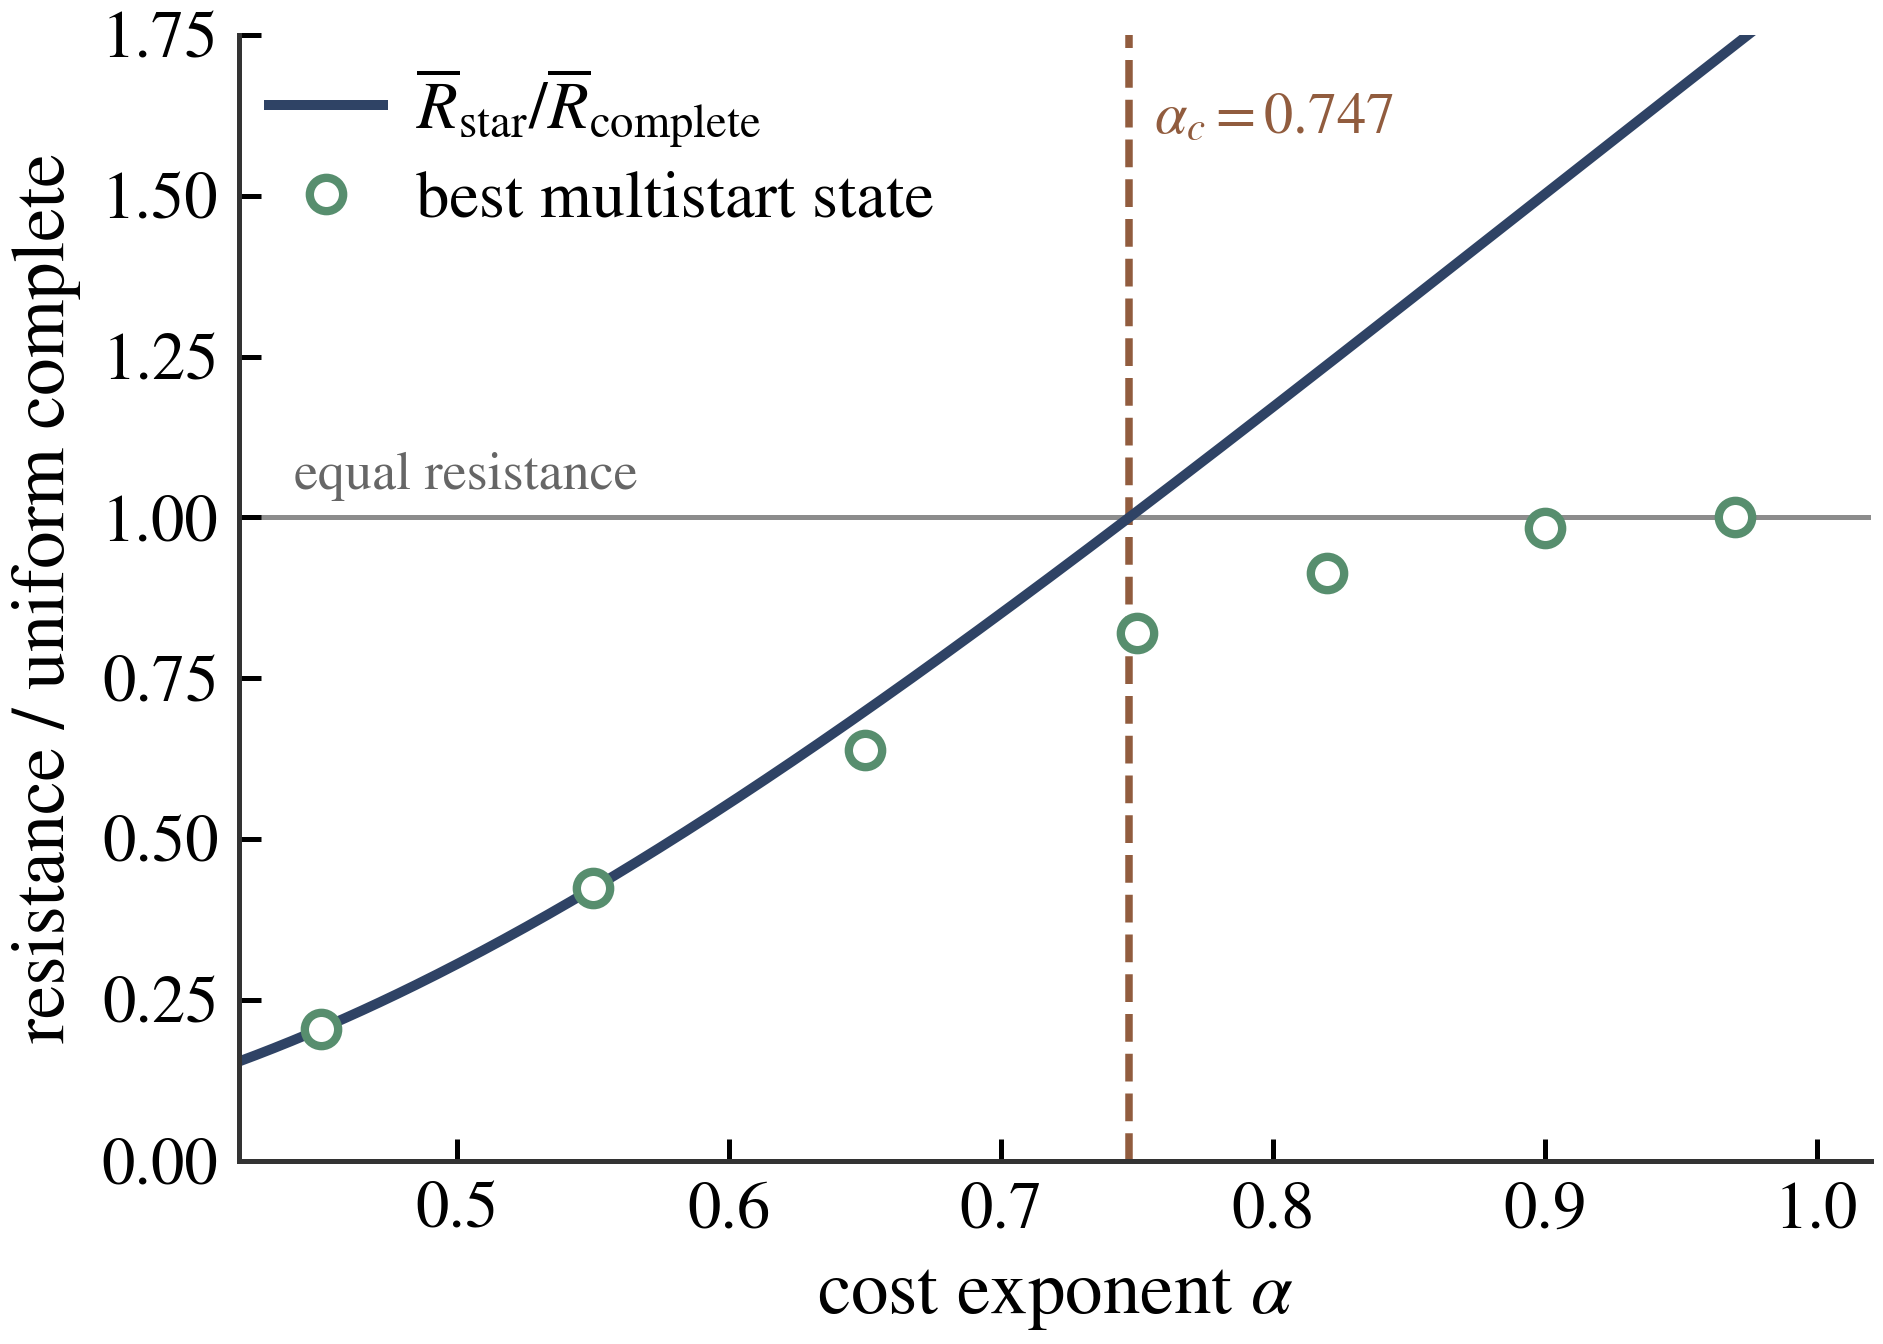

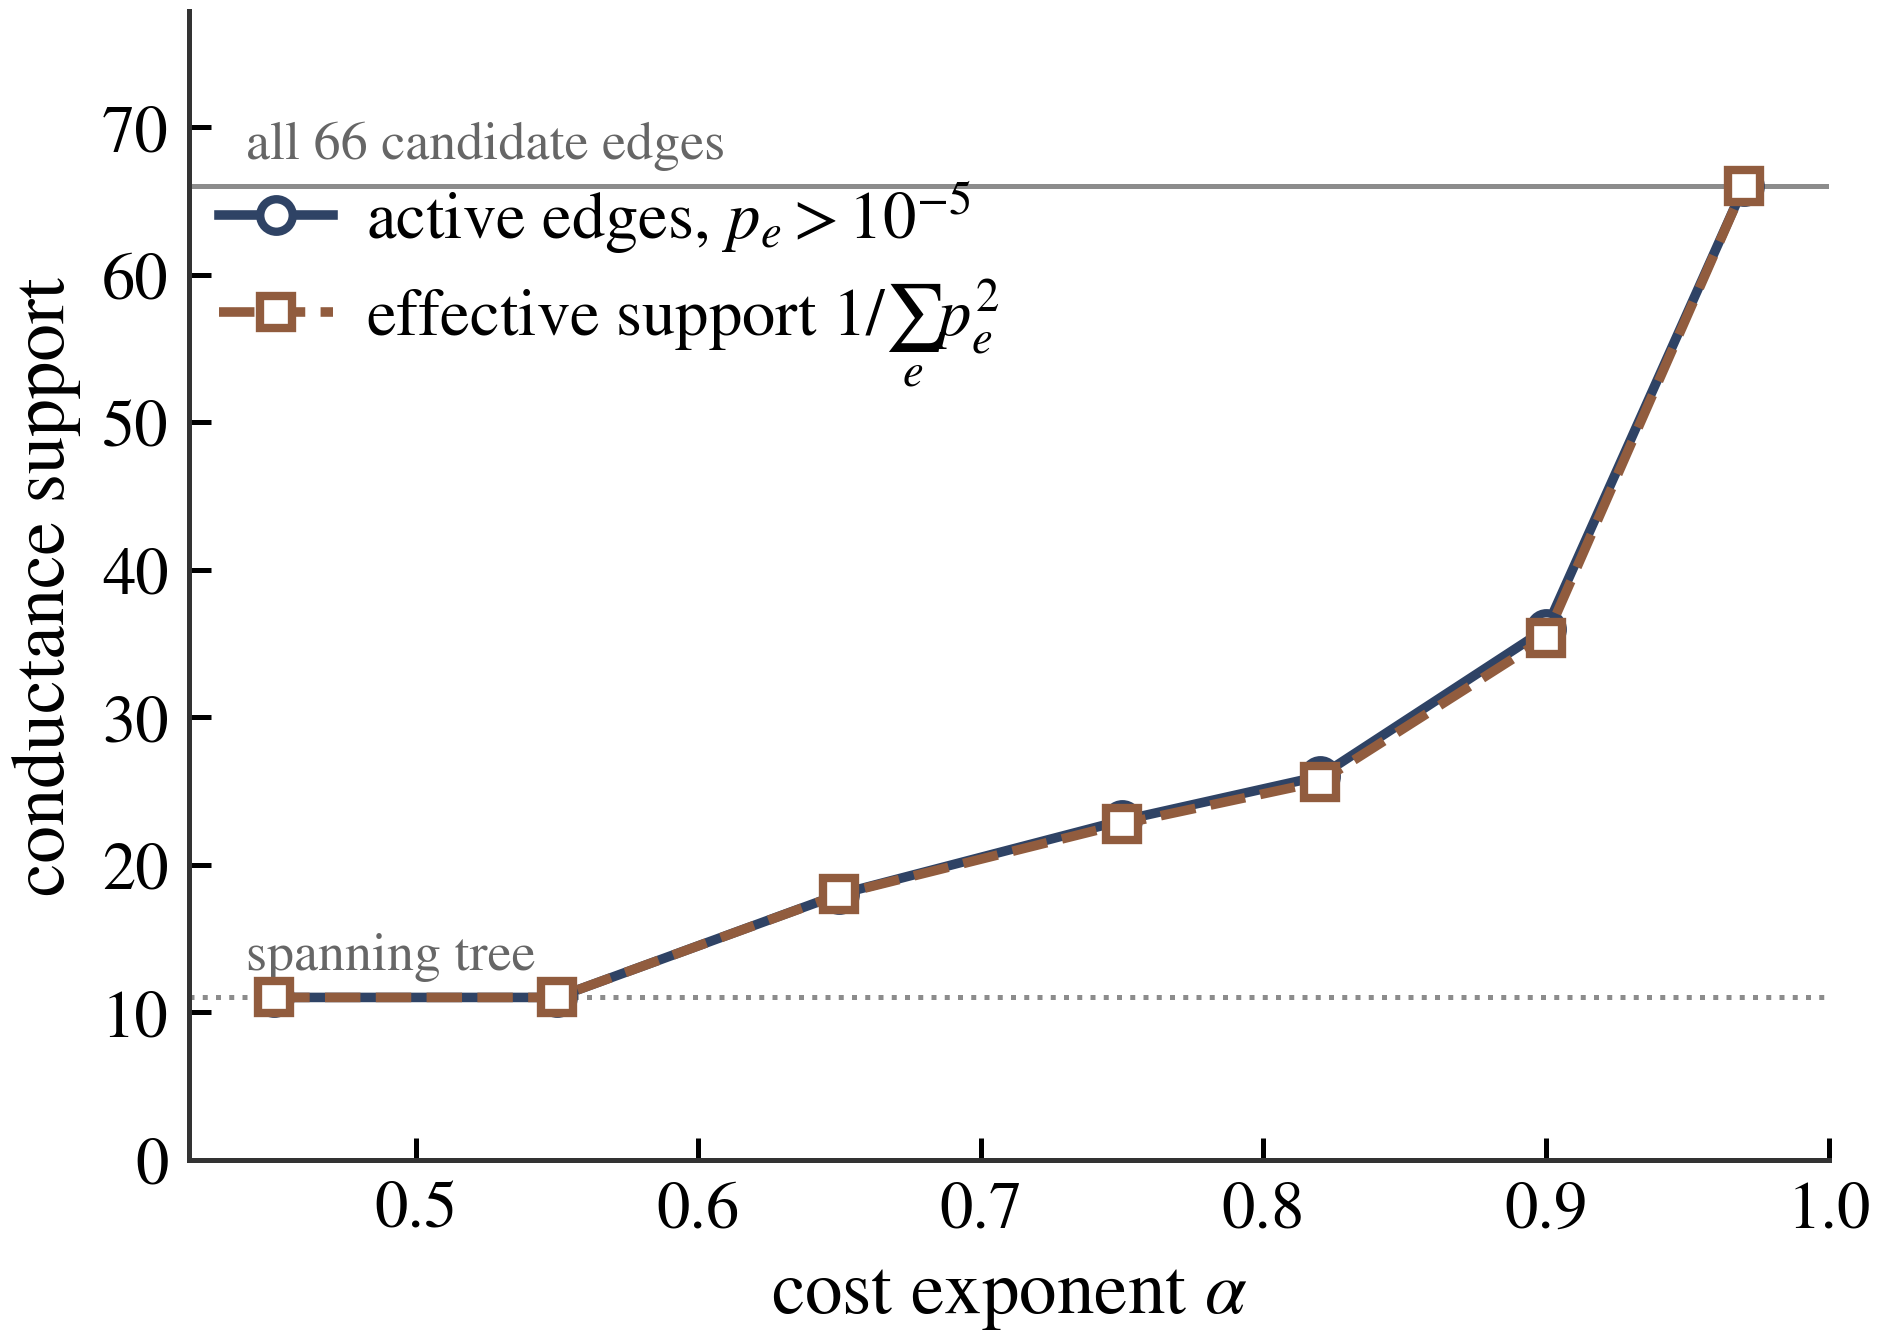

In [8]:
n_c, edges_c, t2 = pa.run_complete()
pa.fig1_star_complete(n_c, t2)
pa.fig3_support(n_c, t2)
print()
print(t2[['alpha','ratio','active','eff_support','spans','frac_at_best','spread_rel',
          'projected_logit_grad_inf','budget_residual']].round(7).to_string(index=False))
display(Image(filename='pre_results/fig1_star_complete.png'))
display(Image(filename='pre_results/fig3_support.png'))

The support is tree-like at strongly concave cost, expands in steps, and returns to the
uniform complete state near $\alpha = 1$. The steps are a property of the best state found
with a fixed search budget. Between one and four of 64 starts reach it.

## 5. Finite size

Equation (12) crosses at $\alpha_c(n)=\log(n/2)/\log(n-1)$, which rises toward one. The sparse
regime should therefore widen with system size rather than disappear. The scan is swept downward
in $\alpha$ with the winning state carried forward, and the grid step is recorded so that these
*resolved* boundary values are not later plotted next to the coarse-grid bounds of the size scan
as if they were the same measurement. Figure 2 is drawn after the size scan, once those bounds
exist.

In [9]:
grid, curves, fs = pa.run_finite_size()
print()
print(fs.round(4).to_string(index=False))

  n=8: alpha_c=0.712 last tree-like alpha=0.55 (grid step 0.05)
  n=12: alpha_c=0.747 last tree-like alpha=0.55 (grid step 0.05)
  n=16: alpha_c=0.768 last tree-like alpha=0.6 (grid step 0.05)
  n=20: alpha_c=0.782 last tree-like alpha=0.6 (grid step 0.05)

 n   m  alpha_c  alpha_last_tree  alpha_grid_step  resolved  frac_at_075
 8  28   0.7124             0.55             0.05      True       0.5714
12  66   0.7472             0.55             0.05      True       0.3485
16 120   0.7679             0.60             0.05      True       0.2667
20 190   0.7820             0.60             0.05      True       0.2158


## 6. Table IV and Fig. 4: how the support grows with size

Section 5 varies $\alpha$ at four small sizes and reports the active fraction of the candidate
set. That fraction falls with $n$ for a trivial reason: the candidate set grows as $n^2$, so the
statement "the active fraction decays as $1/n$" is algebraically implied by "the support grows
linearly" and is not a second finding. The question this section asks is what the support size
does in absolute terms. A dense optimum would give $\mathrm{active}\sim n^2$; a backbone gives
$\mathrm{active}\sim n$.

The scan fixes four concave exponents and pushes $n$ to 64. **It now sweeps $\alpha$ downward at
each size, carrying the winning state into the next exponent**, and keeps the better of the
blind and continued results; `continuation_gain` records where continuation won. Passing
`continuation=False` reproduces the older, biased protocol.

Both the slope *and the intercept* of the growth fit are emitted, with $R^2$ and the number of
points, and the per-node plateau is averaged over the last **four** sizes to match the wording in
the text. An earlier version kept only `polyfit(...)[0]`, so the intercepts quoted in the
manuscript could not be regenerated from this module.

Runtime note: the scan takes roughly an hour on one core with continuation enabled.

The claim this section supports is deliberately weaker than "the support is extensive". Eleven
sizes up to $n=64$ cannot separate linear growth from $n^{1.08}$ or from $n\log n$. What they do
show is that the number of channels per node varies little while the candidate set grows by a
factor of seventeen.

In [10]:
scaling, scaling_fits = pa.run_scaling()
pa.fig4_scaling(scaling, scaling_fits)
print()
print(scaling[['alpha','n','m','active','cycle_rank','is_tree','active_per_node',
               'cycles_per_node','active_fraction','beta_blind','continuation_gain']]
      .round(4).to_string(index=False))
print()
print(scaling_fits.round(4).to_string(index=False))

  scaling alpha=0.9 n=  8: active=  16 beta=   9 active/(n-1)=2.29
  scaling alpha=0.75 n=  8: active=  16 beta=   9 active/(n-1)=2.29   [continuation gained 1.6e-03]
  scaling alpha=0.65 n=  8: active=  12 beta=   5 active/(n-1)=1.71
  scaling alpha=0.55 n=  8: active=   7 beta=   0 active/(n-1)=1.00   [spanning tree]
  scaling alpha=0.9 n= 12: active=  38 beta=  27 active/(n-1)=3.45
  scaling alpha=0.75 n= 12: active=  23 beta=  12 active/(n-1)=2.09
  scaling alpha=0.65 n= 12: active=  18 beta=   7 active/(n-1)=1.64
  scaling alpha=0.55 n= 12: active=  11 beta=   0 active/(n-1)=1.00   [spanning tree]
  scaling alpha=0.9 n= 16: active=  64 beta=  49 active/(n-1)=4.27
  scaling alpha=0.75 n= 16: active=  32 beta=  17 active/(n-1)=2.13
  scaling alpha=0.65 n= 16: active=  27 beta=  12 active/(n-1)=1.80
  scaling alpha=0.55 n= 16: active=  15 beta=   0 active/(n-1)=1.00   [spanning tree]
  scaling alpha=0.9 n= 20: active=  88 beta=  69 active/(n-1)=4.63
  scaling alpha=0.75 n= 20: active

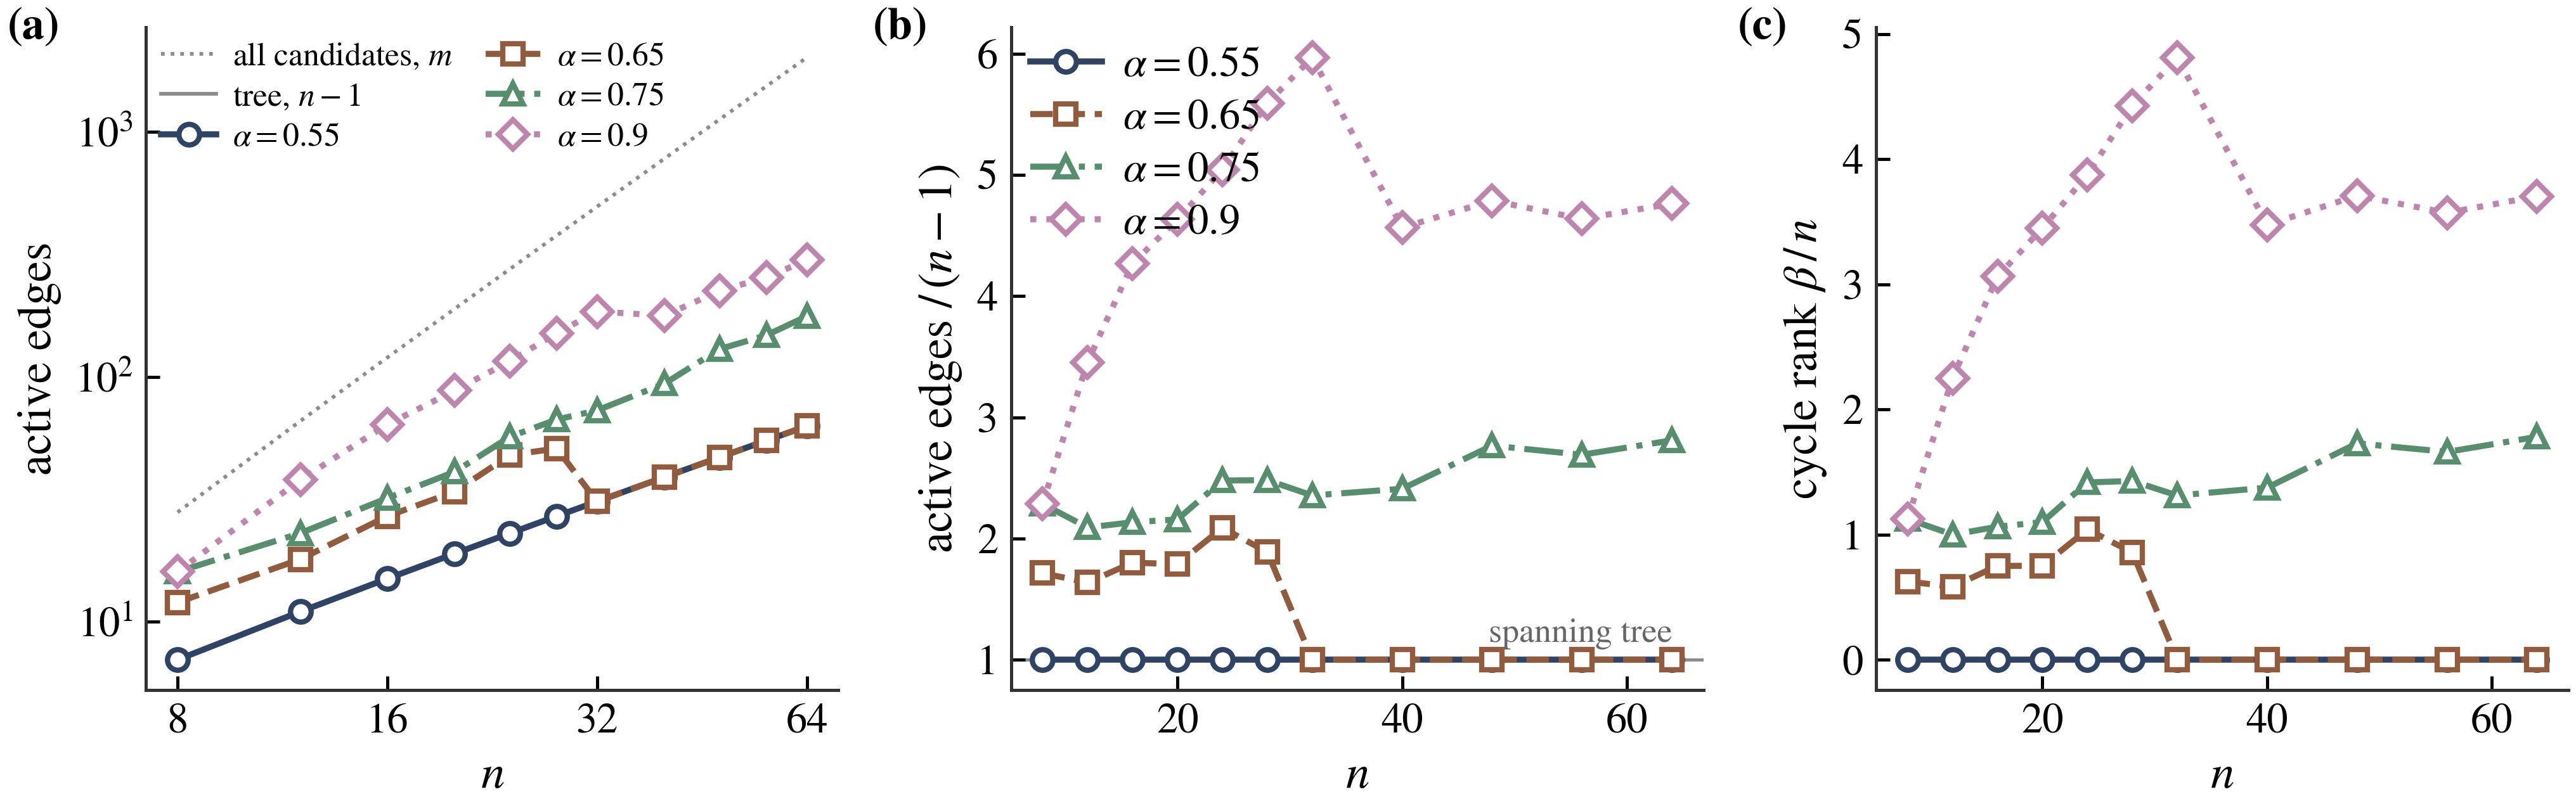

In [11]:
display(Image(filename='pre_results/fig4_scaling.png'))

Figure 2 can now be drawn. Panel (a) carries two different kinds of point and marks them as
such: squares are boundary values **resolved** on the fine $\alpha$ grid, while carets with a
bracket are what the four-exponent size scan actually licenses — a lower bound on the boundary
and an upper bound from the first looped exponent. Drawing the two with the same marker, as an
earlier version did, invites the reader to read a grid artifact as a trend.

In [12]:
bounds = pa.tree_bounds_from_scaling(scaling)
print(bounds.to_string(index=False))
# Fig. 2 is rendered in Sec. 7, once alpha*(n) is available for panel (a).

 n  alpha_tree_lower  alpha_loop_upper  resolved
 8              0.55              0.65     False
12              0.55              0.65     False
16              0.55              0.65     False
20              0.55              0.65     False
24              0.55              0.65     False
28              0.55              0.65     False
32              0.65              0.75     False
40              0.65              0.75     False
48              0.65              0.75     False
56              0.65              0.75     False
64              0.65              0.75     False


## 7. Controls on the search

The central claim of the size scan is partly negative — that no looped state beats the tree at
$\alpha=0.65$ for $n\ge32$ — and negative claims need controls. There are now five, in order of
how much they can establish.

The first raises the blind budget. The second carries the looped state *up* in $n$. Neither can
reach the move that matters, so the third carries a looped state *down* in $\alpha$ at fixed $n$,
and the fourth opens each closed channel by a finite jump: for $0<\alpha<1$ the marginal price
$\alpha a_e w_e^{\alpha-1}$ diverges as $w_e\to0$, so opening a channel is not an infinitesimal
move and no gradient step can make it. Raising the number of blind starts does not test that —
the move is absent from the search, not undersampled. The fifth varies the start-set realization.

In [13]:
budget = pa.run_start_budget()
print()
print(budget.round(6).to_string(index=False))

  alpha=0.65 n=32 starts=  28: R=381.631590 active=  31 beta=   0
  alpha=0.65 n=32 starts=  64: R=381.631590 active=  31 beta=   0
  alpha=0.65 n=32 starts= 144: R=381.631590 active=  31 beta=   0
  alpha=0.65 n=40 starts=  28: R=546.797241 active=  39 beta=   0
  alpha=0.65 n=40 starts=  64: R=546.797241 active=  39 beta=   0
  alpha=0.65 n=40 starts= 144: R=546.797241 active=  39 beta=   0
  alpha=0.9 n=40 starts=  28: R=75.208826 active= 178 beta= 139
  alpha=0.9 n=40 starts=  64: R=75.198266 active= 179 beta= 140
  alpha=0.9 n=40 starts= 144: R=75.198266 active= 179 beta= 140
  alpha=0.65 n=32: relative change in best resistance across budgets = 0.00e+00
  alpha=0.65 n=40: relative change in best resistance across budgets = 0.00e+00
  alpha=0.9 n=40: relative change in best resistance across budgets = 1.40e-04

 alpha  n  starts     R_best  active  cycle_rank  frac_at_best
  0.65 32      28 381.631590      31           0      0.071429
  0.65 32      64 381.631590      31          

In [14]:
seeded = pa.run_seeded_continuation(alpha=0.65, n_from=28, n_to=(32, 40))
print()
print(seeded.round(8).to_string(index=False))

  source state: alpha=0.65 n=28 active=51 beta=24 R=306.903801
  n=32: blind R=381.631590 (active=31, beta=0)  |  seeded R=381.631590 (active=31, beta=0)  -> loopless state survives
  n=40: blind R=546.797241 (active=39, beta=0)  |  seeded R=546.797241 (active=39, beta=0)  -> loopless state survives

 alpha  n    R_blind  active_blind  beta_blind   R_seeded  active_seeded  beta_seeded  seeded_is_better  rel_gap
  0.65 32 381.631590            31           0 381.631590             31            0             False      0.0
  0.65 40 546.797241            39           0 546.797241             39            0             False      0.0


Continuation in $\alpha$ at fixed $n=32$. The looped state that has to be excluded at
$\alpha=0.65$ exists at $\alpha=0.75$ on the same candidate graph, so it is handed to the
optimizer directly rather than left to Dirichlet sampling in roughly 500 dimensions. The blind
result is recomputed at every rung, which makes this simultaneously a control on the conclusion
and a measurement of the blind protocol's bias: read `beta_deficit`.

In [15]:
alpha_cont = pa.run_alpha_continuation(n=32)
print()
print(alpha_cont.round(8).to_string(index=False))

  alpha=0.75: blind R=161.057300 (active= 73, beta= 42) | continued R=161.057300 (active= 73, beta= 42) | gain=+0.00e+00
  alpha=0.72: blind R=204.746537 (active= 70, beta= 39) | continued R=204.332142 (active= 73, beta= 42) | gain=+2.02e-03
  alpha=0.7: blind R=242.907214 (active= 64, beta= 33) | continued R=242.190415 (active= 73, beta= 42) | gain=+2.95e-03
  alpha=0.68: blind R=289.899042 (active= 65, beta= 34) | continued R=288.699362 (active= 71, beta= 40) | gain=+4.14e-03
  alpha=0.66: blind R=350.026859 (active= 58, beta= 27) | continued R=349.004271 (active= 71, beta= 40) | gain=+2.92e-03
  alpha=0.65: blind R=381.631590 (active= 31, beta=  0) | continued R=381.631590 (active= 31, beta=  0) | gain=+0.00e+00

 alpha  n    R_blind  active_blind  beta_blind     R_cont  active_cont  beta_cont  rel_gain  beta_deficit
  0.75 32 161.057300            73          42 161.057300           73         42  0.000000             0
  0.72 32 204.746537            70          39 204.332142     

Localizing the collapse. Fig. 2(a) reports the largest *tested* exponent whose best state is
tree-like, which on a four-exponent grid is a bound. A fine grid swept downward with continuation
localizes the collapse instead, and shows whether it is gradual or abrupt — which is the question
Kaiser, Ronellenfitsch and Witthaut answer for prescribed loading, where loop formation sets in
discontinuously.

The sweep runs from $\alpha=0.700$ downward in steps of 0.005 with continuation at
all eleven sizes, and stops three steps after the first spanning tree. This is the
longest cell in the notebook: $n=48$–$64$ dominate and the whole cell takes on the
order of an hour on one core. The summary table it prints is the source of every
$\alpha^{*}(n)$ value, and of the active-edge count and cycle rank immediately above
the collapse, quoted in Secs. V and VIII and in the Conclusion of the manuscript.

In [ ]:
astar, astar_summary = pa.run_alpha_star_line()

  n=8 alpha=0.700: active= 12 beta=  5 R=23.751242 (blind beta=  5)
  n=8 alpha=0.695: active= 12 beta=  5 R=24.365322 (blind beta=  5)
  n=8 alpha=0.690: active= 12 beta=  5 R=25.004527 (blind beta=  5)
  n=8 alpha=0.685: active= 12 beta=  5 R=25.670204 (blind beta=  5)
  n=8 alpha=0.680: active= 12 beta=  5 R=26.363788 (blind beta=  5)
  n=8 alpha=0.675: active= 12 beta=  5 R=27.086809 (blind beta=  5)
  n=8 alpha=0.670: active= 12 beta=  5 R=27.840900 (blind beta=  5)
  n=8 alpha=0.665: active= 12 beta=  5 R=28.627803 (blind beta=  5)
  n=8 alpha=0.660: active= 12 beta=  5 R=29.449381 (blind beta=  5)
  n=8 alpha=0.655: active= 12 beta=  5 R=30.307628 (blind beta=  5)
  n=8 alpha=0.650: active= 12 beta=  5 R=31.204676 (blind beta=  5)
  n=8 alpha=0.645: active= 12 beta=  5 R=32.142807 (blind beta=  4)
  n=8 alpha=0.640: active= 12 beta=  5 R=33.124470 (blind beta=  4)
  n=8 alpha=0.635: active= 12 beta=  5 R=34.152290 (blind beta=  4)
  n=8 alpha=0.630: active= 12 beta=  5 R=35.2290

The summary below is the source of every $\alpha^{*}(n)$ value quoted in the
manuscript, together with the active-edge count and cycle rank of the looped state
immediately above the collapse. It is printed in its own cell because the sweep
above emits several hundred lines and some front ends truncate long outputs.

In [17]:
print(astar_summary.to_string(index=False))

 n  alpha_star  alpha_first_looped  active_above  beta_above  single_transition  tree_steps_below
 8       0.555               0.560             9           2               True                 4
12       0.585               0.590            18           7               True                 4
16       0.610               0.615            25          10               True                 4
20       0.630               0.635            37          18               True                 4
24       0.635               0.640            41          18               True                 4
28       0.645               0.650            57          30               True                 4
32       0.650               0.655            64          33               True                 4
40       0.660               0.665            80          41               True                 4
48       0.665               0.670           101          54               True                 4
56       0.670      

**Fig. 2.** Panel (a) draws $\alpha^{*}(n)$ from the summary just computed against
the analytic crossing $\alpha_c(n)$; panel (b) uses the finite-size curves of Sec. 5.
The figure is rendered here rather than in Sec. 5 because panel (a) needs the
fine-grid sweep.

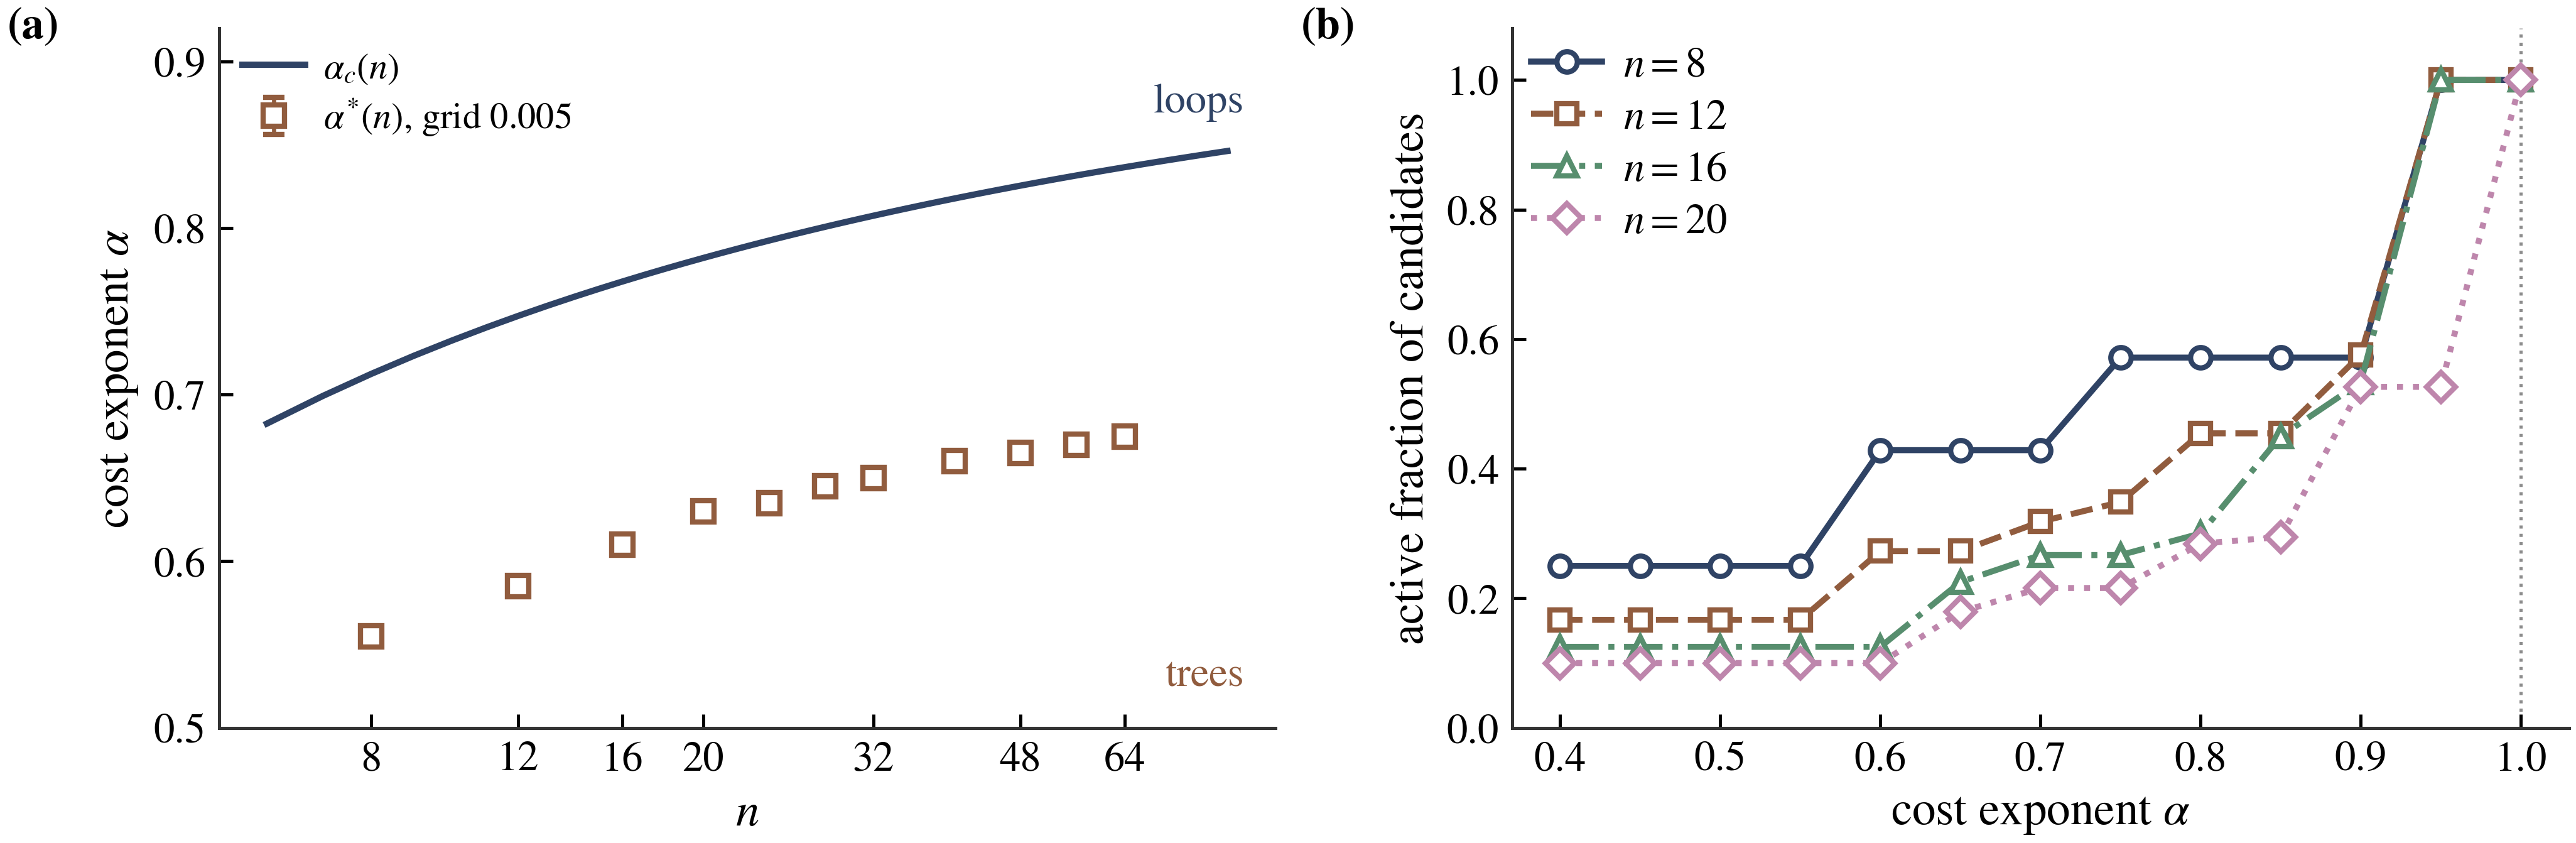

In [18]:
pa.fig2_finite_size(grid, curves, fs, astar=astar_summary)
display(Image(filename='pre_results/fig2_finite_size.png'))

The finite-jump insertion test. Every closed edge is given a finite share $\varepsilon$ in turn,
the rest are renormalized, and the state is refined. If nothing beats the incumbent, the support
is stable against every single-channel opening at that scale.

In [19]:
ins = pa.run_insertion_test(alpha=0.65, n=32)
print()
print(ins.to_string(index=False))

  base alpha=0.65 n=32: R=381.63159029 active=31 beta=0, 465 closed edges to probe
  eps=0.01: 0/465 insertions beat the incumbent; best R=381.63159029 (gap +1.753e-12)
  eps=0.02: 0/465 insertions beat the incumbent; best R=381.63159029 (gap +1.444e-12)
  eps=0.05: 0/465 insertions beat the incumbent; best R=381.63159029 (gap +1.764e-12)

 alpha  n  eps  n_insertions  n_improving  best_after best_edge      rel_gap
  0.65 32 0.01           465            0   381.63159  (13, 21) 1.753272e-12
  0.65 32 0.02           465            0   381.63159  (12, 26) 1.444204e-12
  0.65 32 0.05           465            0   381.63159   (4, 30) 1.764145e-12


In [ ]:
seedrob = pa.run_seed_robustness(alpha=0.65, n=32)
print()
print(seedrob.round(8).to_string(index=False))

## 8. The support threshold

The controls above concern the search. This one concerns the measurement: every active-edge count
and cycle rank in this work inherits a cut on $p_e$.

An earlier version of this control took the state returned by `multistart` — whose shares below
$10^{-5}$ had already been set to exactly zero by the refinement step — and recounted it at three
thresholds. That recount cannot disagree with the cut that produced the support, so it established
only that the reported states are stable *after* truncation, which the caveat in the manuscript
said explicitly. The version below does what that caveat asks for: it runs the search once with
pruning disabled, then reruns the refinement from that same pretruncation solution at each cut, so
the counts are genuinely functions of the threshold. The threshold-free effective support
$1/\sum_e p_e^2$ is reported alongside.

In [ ]:
thresh = pa.run_threshold_sensitivity()
print()
print(thresh.round(8).to_string(index=False))

## 9. Table V and Figs. 5 and 6: spatial network

Two rows are new. The $\alpha=1/2$ row with $a_e\propto\ell_e^{3/2}$ is the Hagen–Poiseuille
fixed-volume law derived in Sec. II B, so the physically motivated case is now computed and not
only derived; it lands in the concave regime and gives a near-tree backbone, which is the point of
contact with vascular architecture. The $\alpha=1$ row is the convex boundary, where Sec. III
predicts a unique but possibly sparse optimum — unequal $a_e$ should price some edges out, and the
`priced_out` column reports how many.

The start seed is now the same at every exponent. Using `int(alpha*1000)+5` gave each exponent a
different set of random starts, so the progression across $\alpha$ mixed the effect of the cost law
with a change of initial conditions.

  spatial alpha=0.5 a_e=l^1.5: active= 29 cycles=  2 N_p=18.4 N_w=15.8 gain=15.27
  spatial alpha=0.55 a_e=l^1: active= 30 cycles=  3 N_p=23.2 N_w=24.5 gain=6.07
  spatial alpha=0.75 a_e=l^1: active= 32 cycles=  5 N_p=22.6 N_w=23.5 gain=2.89
  spatial alpha=0.95 a_e=l^1: active= 60 cycles= 33 N_p=34.7 N_w=38.8 gain=2.07
  spatial alpha=1 a_e=l^1: active= 86 cycles= 59 N_p=38.4 N_w=44.8 gain=1.99
  spatial alpha=1.25 a_e=l^1: active= 95 cycles= 68 N_p=36.9 N_w=56.9 gain=1.77
  spatial alpha=2 a_e=l^1: active= 95 cycles= 68 N_p=30.9 N_w=76.2 gain=1.48

 alpha  a_exponent                     law  active  cycle_rank  priced_out  eff_support  eff_support_w  w_max  access_gain  n_starts
  0.50         1.5 Poiseuille fixed volume      29           2          66      18.4376        15.7572 1.7953      15.2709        64
  0.55         1.0          length penalty      30           3          65      23.1848        24.4665 0.1527       6.0701        64
  0.75         1.0          length penalty  

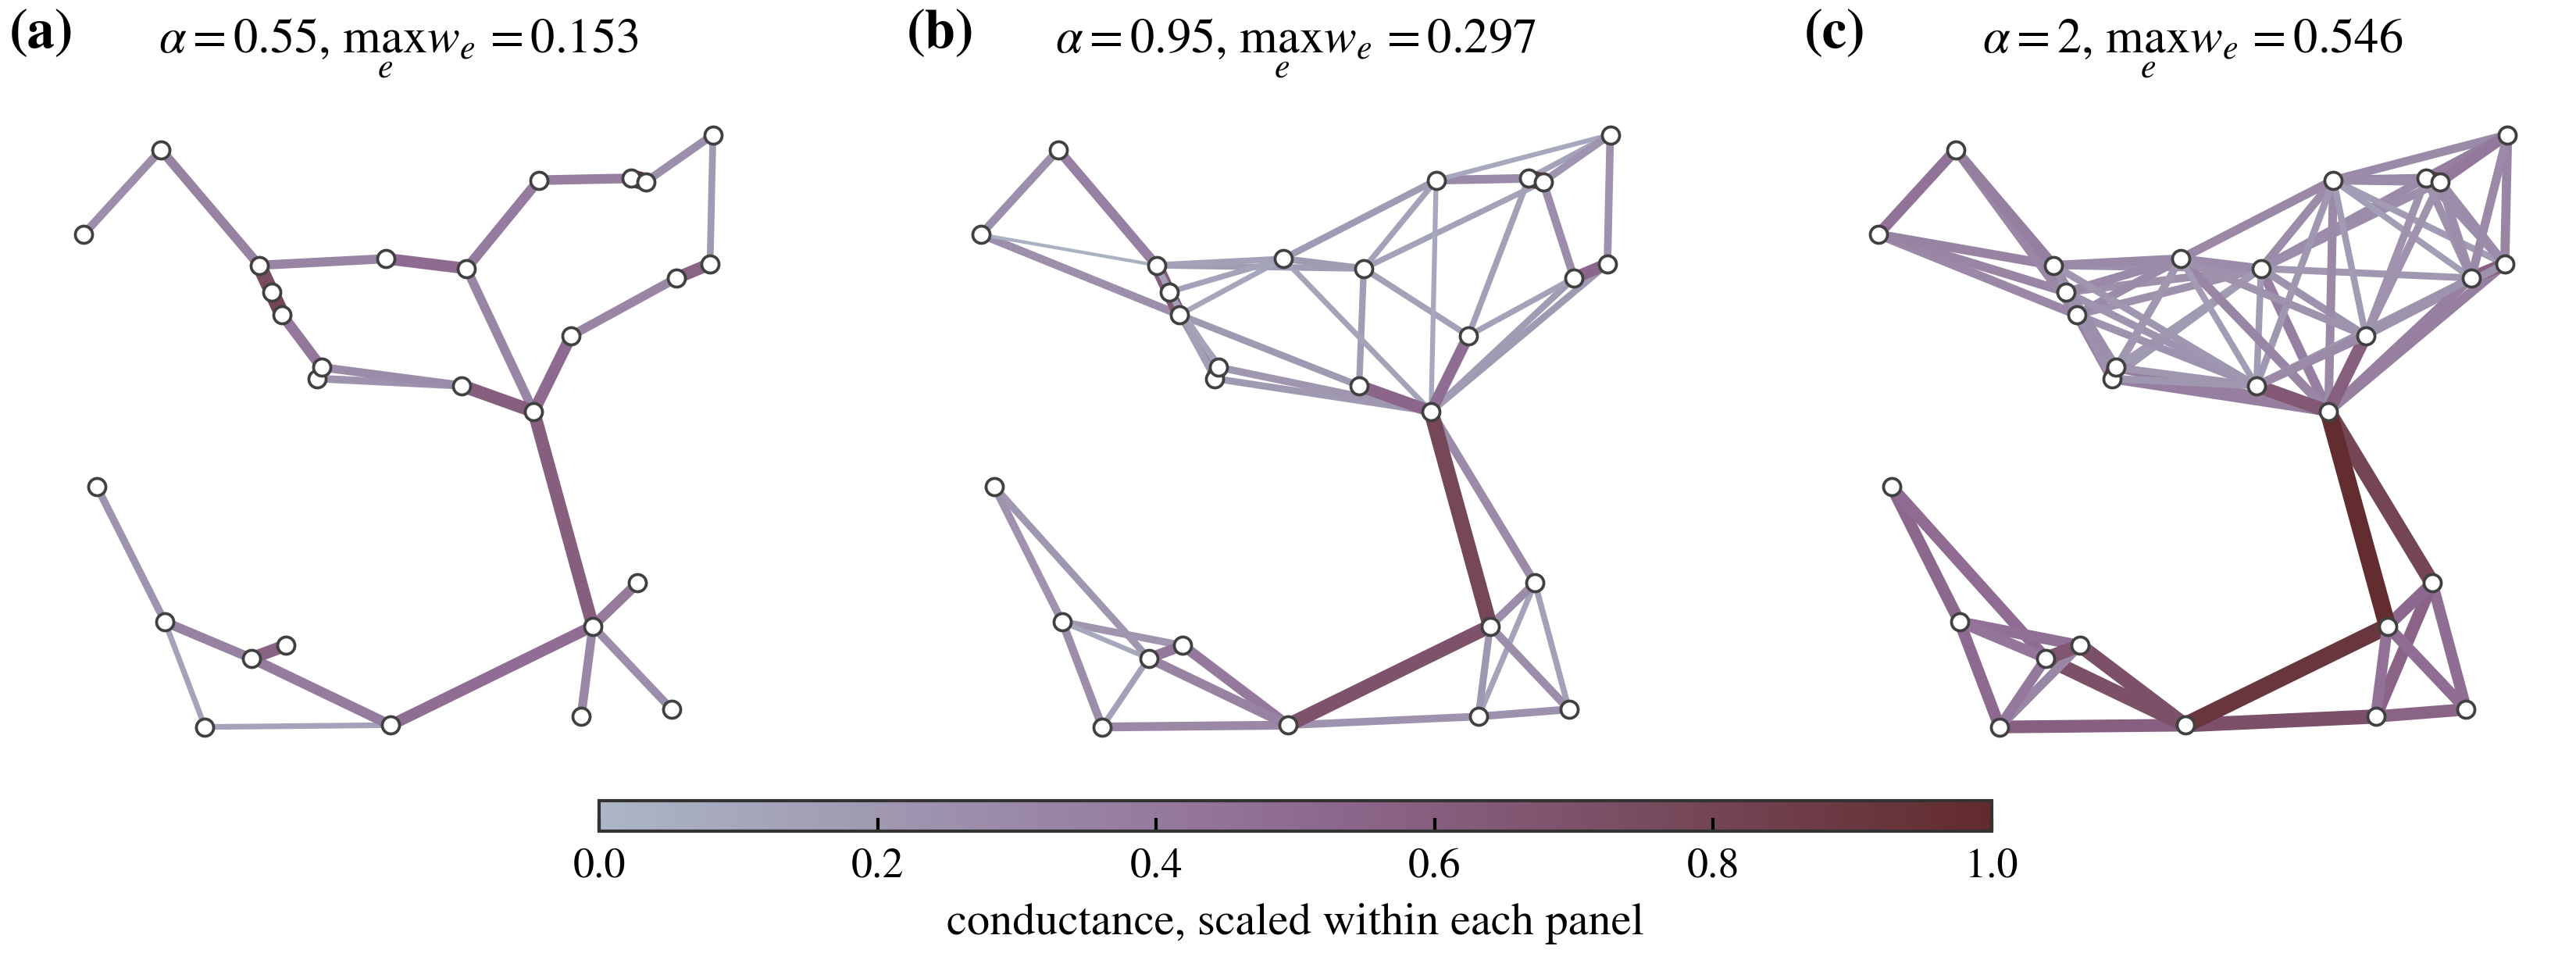

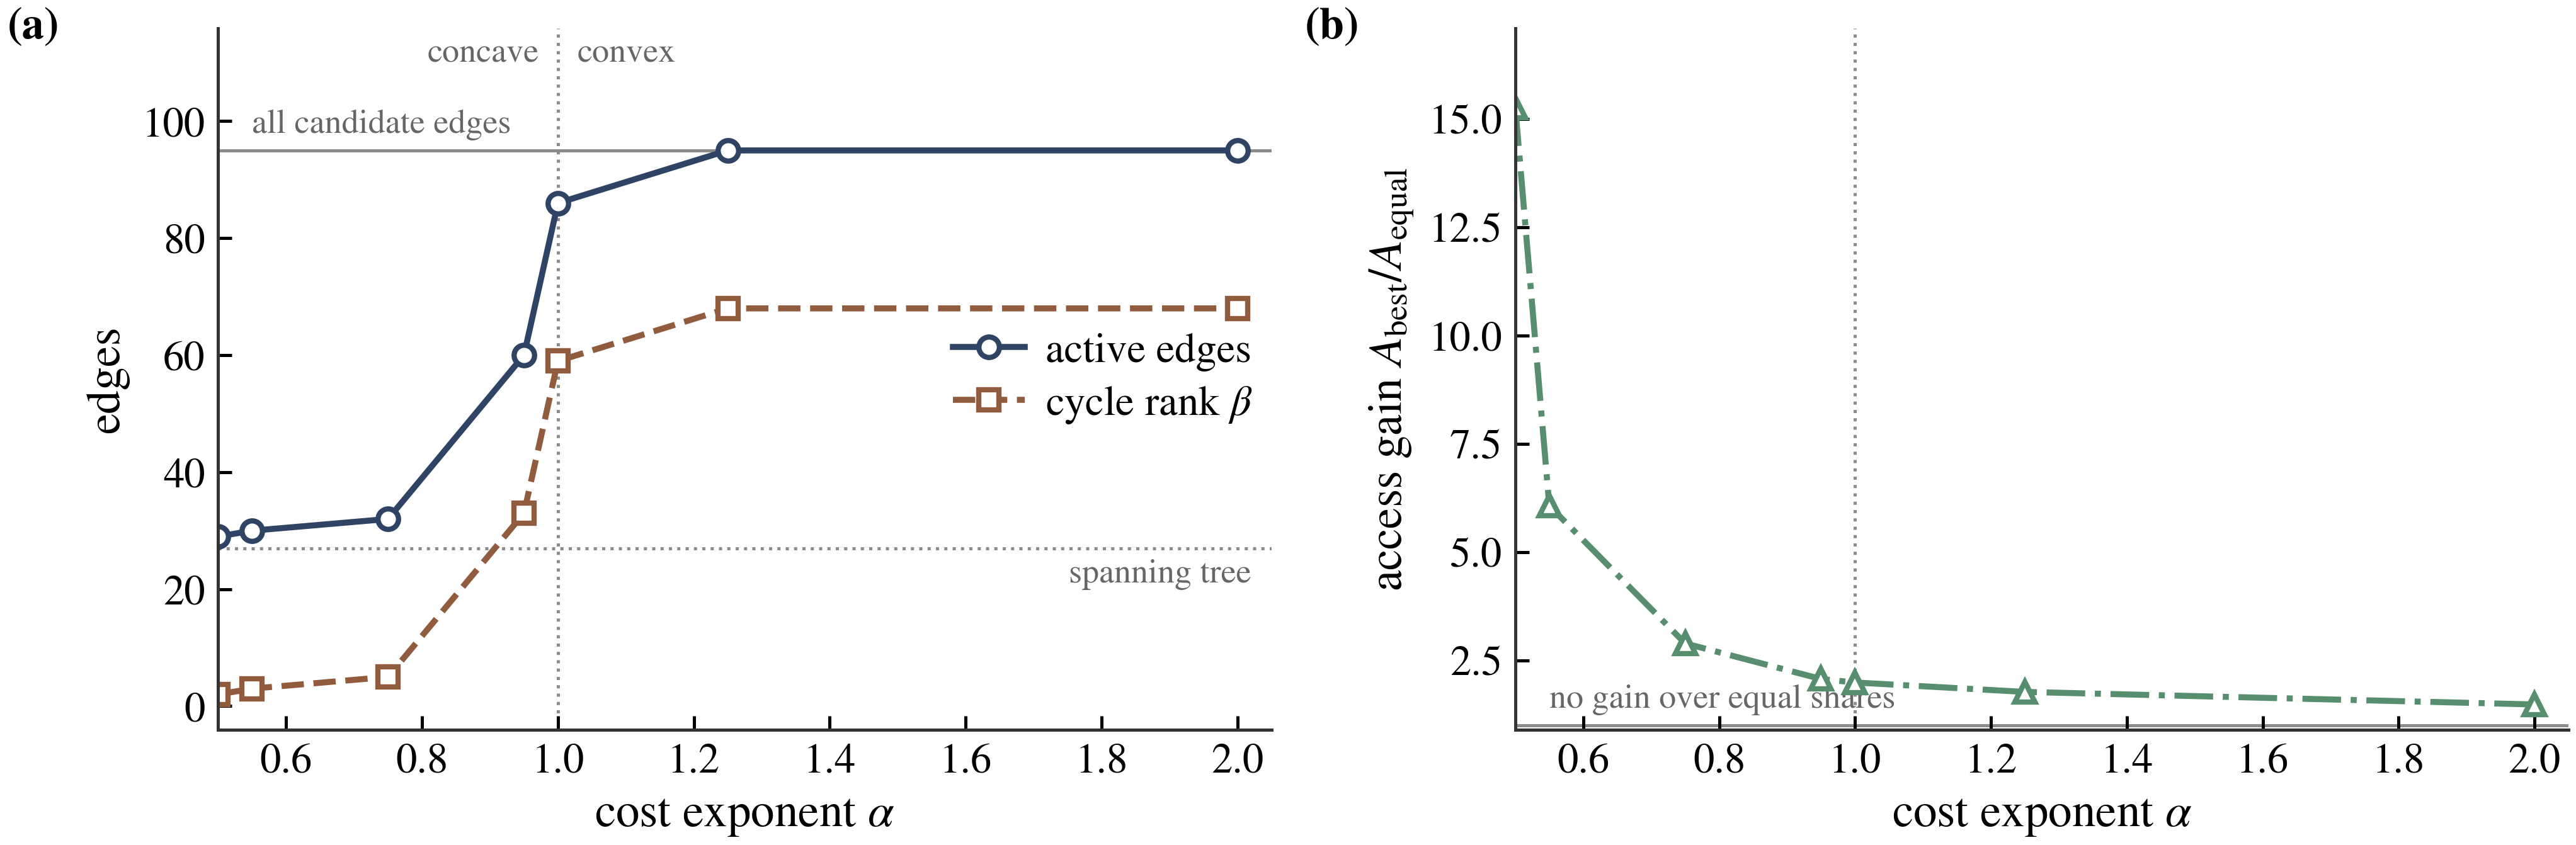

In [22]:
spatial = pa.run_spatial()
pa.fig5_6_spatial(spatial)
print()
print(spatial[4][['alpha','a_exponent','law','active','cycle_rank','priced_out','eff_support',
                  'eff_support_w','w_max','access_gain','n_starts']].round(4).to_string(index=False))
display(Image(filename='pre_results/fig5_spatial_states.png'))
display(Image(filename='pre_results/fig6_spatial_transition.png'))

The spatial results reported in the manuscript are taken from the table generated directly above. Re-execution therefore cannot silently retain an older local minimum in the text or figures.

## 10. Table VI: the loading ensemble

For the all-pairs load we retain the same multistart calculation. For one prescribed source-sink pair and $0<\alpha<1$, the control state is analytic. Thomson's principle gives a unit-flow cost proportional to $\sum_e a_e^{1/(\alpha+1)}|f_e|^{2\alpha/(\alpha+1)}$. After circulations are canceled, unit flows form the convex hull of simple source-sink path flows. Because the exponent $2\alpha/(\alpha+1)$ is below one, this functional is concave on nonnegative flows and attains a minimum at an extreme point of that polytope; its extreme points are simple paths. On a fixed path, $R_{st}=[\sum_{e\in P}a_e^{1/(\alpha+1)}]^{1+1/\alpha}$. The exact control is therefore the shortest path under transformed edge cost $a_e^{1/(\alpha+1)}$; for the equal edge prices used here it is the six-hop path. This removes the spurious local state previously reported at $\alpha=0.55$.

In [ ]:
t4 = pa.run_loading()
print()
print(t4[['alpha','eff_allpairs','active_allpairs','cycles_allpairs',
          'path_edges','cycles_path','eff_path']].round(4).to_string(index=False))
print()
print('All-pairs support grows and accumulates cycles as alpha approaches one.')
print('The exact single-pair control is a loopless six-edge path throughout the tested concave regime.')

## 11. Fig. 7: local sensitivity in a barbell network

This cell reproduces Sec. XI and Fig. 7 on `nx.barbell_graph(8, 2)` with unit conductances, unit edge-price coefficients, and $\alpha=2$. For each edge it evaluates $\widetilde{\kappa}_e=(\partial A/\partial w_e)/(\partial C_\alpha/\partial w_e)$ from Eq. (7). The second panel sums incident edge scores for the equal-increment node direction used in the manuscript.

  barbell_graph(8, 2), alpha=2: kappa_max/kappa_min=144 = 10^2.16

              graph  n  m  alpha  conductance edge_price  kappa_min  kappa_max  max_min_ratio  orders_of_magnitude
barbell_graph(8, 2) 18 59    2.0          1.0       unit   0.000512    0.07368          144.0             2.158362


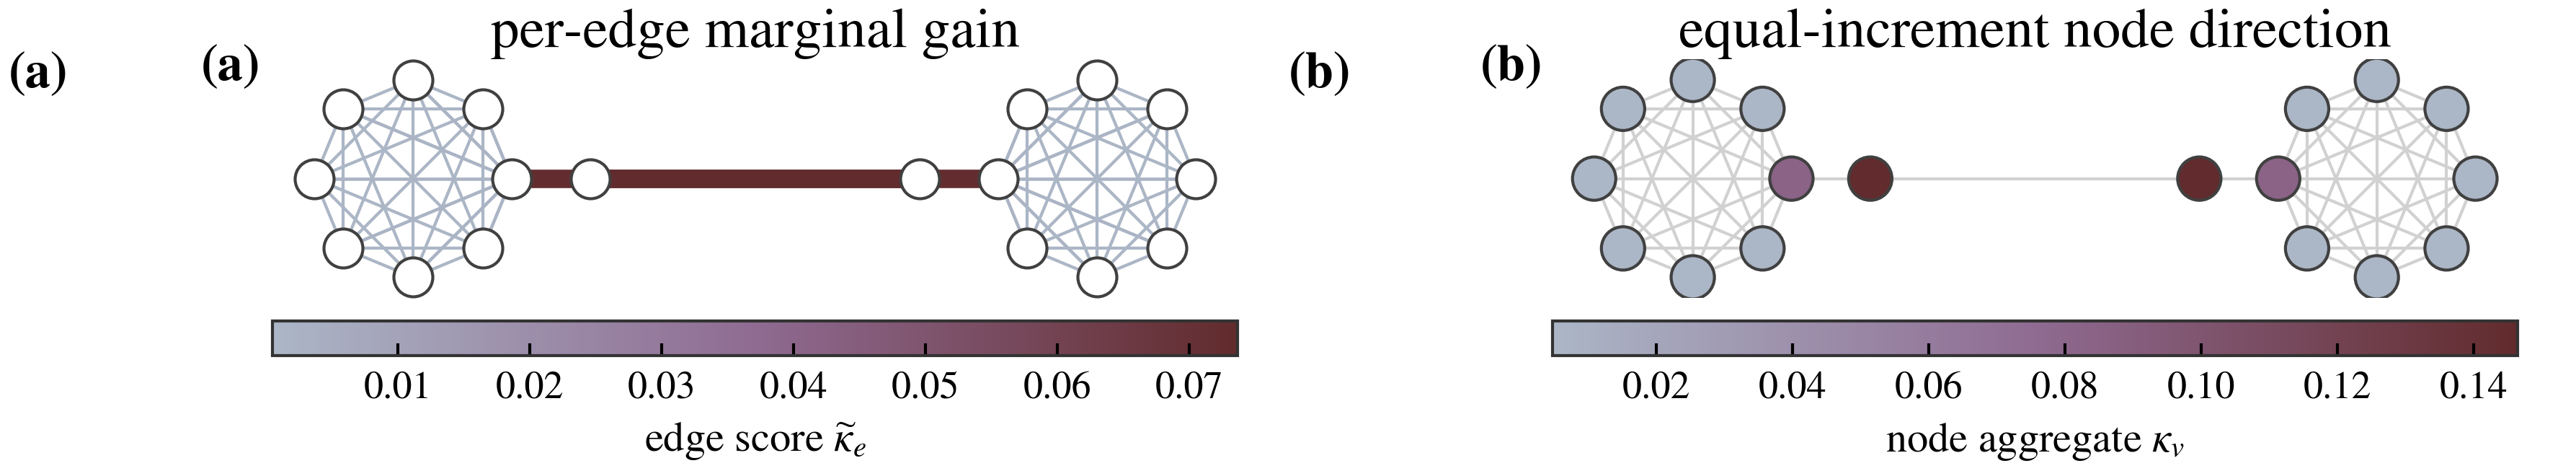

In [24]:
barbell = pa.run_barbell_sensitivity()
pa.fig7_barbell(barbell)
print()
print(barbell['summary'].round(8).to_string(index=False))
display(Image(filename='pre_results/fig7_barbell.png'))

## 12. Files written

In [25]:
import os
for f in sorted(os.listdir('pre_results')):
    print(' ', f)

  alpha_continuation.tsv
  alpha_star_line.tsv
  alpha_star_summary.tsv
  barbell_sensitivity.tsv
  barbell_sensitivity_summary.tsv
  complete_weights.json
  fig1_star_complete.png
  fig2_finite_size.png
  fig3_support.png
  fig4_scaling.png
  fig5_spatial_states.png
  fig6_spatial_transition.png
  fig7_barbell.png
  finite_size.tsv
  finite_size_curves.npz
  insertion_test.tsv
  scaling_fits.tsv
  seed_robustness.tsv
  seeded_continuation.tsv
  spatial_network.npz
  spatial_weights.json
  start_budget.tsv
  table1_convex.tsv
  table2_complete.tsv
  table3_scaling.tsv
  table4_spatial.tsv
  table5_loading.tsv
  threshold_sensitivity.tsv
